In [1]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### M2 model -> 추정총매출 + 가중치 적용 + 다음 분기 폐업수 예측
시간순번 변수 제외

In [5]:
import pandas as pd
import numpy as np
import lightgbm as lgb

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr


# =========================================================
# 1. 데이터 불러오기
# =========================================================

file_path = (
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리\[새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv"
)

df = pd.read_csv(file_path)

print("전체 데이터:", df.shape)
print(df["기준분기"].value_counts().sort_index())


# =========================================================
# 2. 피처 및 타겟 설정
# =========================================================

features = [
    # 시간 (시간순번 제거)
    "분기번호",
    
    # 업태
    "업태구분_2진수",
    
    # 읍면동 × 업태 사업체 구성
    "읍면동업태_영업점포수",
    "평균업력개월",
    "업력1년미만_점포비중",
    "평균시설규모",
    "중앙시설규모",
    "소규모점포비중",
    "다중이용업소비중",
    
    # 법정동 수요 / 경쟁 환경
    "법정동_실제총인구",
    "법정동_인구증감률_QoQ",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_전체점포수",
    "법정동_인구천명당_동일업태점포수",
    
    # 읍면동 × 업태 상권 상태
    "읍면동업태_분기개업수",
    "읍면동업태_분기폐업수",
    "읍면동업태_점포비중",
    "읍면동업태_직전분기말점포수",
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_점포수증감률",
    "읍면동업태_폐업률_lag1",
    "읍면동업태_폐업률_lag4",
    "읍면동업태_폐업률_4Q평균",
    "읍면동업태_폐업률_전분기대비증감",

    "NICE_총매출_만원"
]

# 타겟을 폐업수(건수)로 변경
target_count = "다음분기_폐업수"
# 최종 평가는 여전히 폐업률로 진행하기 위해 별도 저장
target_rate_eval = "다음분기_폐업률" 

print("\nFeature 수:", len(features))


# =========================================================
# 3. Train / Test 분할
# =========================================================

train_df = df[df["기준연도"] <= 2025].copy()
test_df = df[df["기준연도"] == 2026].copy()

X_train = train_df[features].copy()
y_train_count = train_df[target_count].astype(float)

X_test = test_df[features].copy()
y_test_count = test_df[target_count].astype(float)

# 평가를 위한 실제 폐업률
y_test_rate = test_df[target_rate_eval].astype(float) 

print("Train:", len(train_df))
print("Test :", len(test_df))


# =========================================================
# 4. LightGBM (Poisson 모델)
# =========================================================

model = lgb.LGBMRegressor(
    objective="poisson",       # 건수 예측에 최적화된 포아송 회귀 적용
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=30,      # 과소적합 방지를 위해 30으로 완화
    reg_alpha=0.1,
    reg_lambda=1.0,
    colsample_bytree=0.9,
    subsample=0.9,
    max_depth=-1,
    n_estimators=120,
    random_state=42,
    verbosity=-1,
    force_col_wise=True,
    n_jobs=4
)


# =========================================================
# 5. 학습
# 포아송 회귀는 값의 크기 자체가 비중 역할을 하므로 Weight 생략 가능
# =========================================================

model.fit(X_train, y_train_count)


# =========================================================
# 6. 예측 및 비율 변환
# =========================================================

# 1) 먼저 다음분기 '폐업수'를 예측
pred_count = model.predict(X_test)

# 2) 예측된 폐업수를 기준 영업점포수로 나누어 '폐업률'로 변환
# 분모가 0인 경우를 방지하기 위해 매우 작은 값(1e-9)을 더해주는 것이 안전할 수 있습니다.
pred_rate = pred_count / (X_test["읍면동업태_영업점포수"] + 1e-9)

# 3) 폐업률은 0~1 사이이므로 클리핑 적용
y_pred_rate = np.clip(pred_rate, 0, 1)


# =========================================================
# 7. 평가 (실제 폐업률 vs 예측 폐업률)
# =========================================================

test_weight = np.sqrt(test_df["읍면동업태_영업점포수"].astype(float))

mae = mean_absolute_error(y_test_rate, y_pred_rate)
rmse = np.sqrt(mean_squared_error(y_test_rate, y_pred_rate))

wmae = np.average(np.abs(y_test_rate - y_pred_rate), weights=test_weight)
wrmse = np.sqrt(np.average((y_test_rate - y_pred_rate) ** 2, weights=test_weight))

pearson = pearsonr(y_test_rate, y_pred_rate)[0]
spearman = spearmanr(y_test_rate, y_pred_rate)[0]
r2 = r2_score(y_test_rate, y_pred_rate)

print("\n==========================================")
print(" 타겟변경: 다음분기_폐업수 예측 후 비율 변환 (시간순번 제외)")
print("==========================================")
print(f"MAE      : {mae:.6f} ({mae*100:.3f}%p)")
print(f"RMSE     : {rmse:.6f} ({rmse*100:.3f}%p)")
print(f"WMAE     : {wmae:.6f} ({wmae*100:.3f}%p)")
print(f"WRMSE    : {wrmse:.6f} ({wrmse*100:.3f}%p)")
print(f"Pearson  : {pearson:.3f}")
print(f"Spearman : {spearman:.3f}")
print(f"R2       : {r2:.3f}")


# =========================================================
# 8. Feature Importance
# =========================================================

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values("Importance", ascending=False).reset_index(drop=True)
importance_df["Importance_pct"] = (importance_df["Importance"] / importance_df["Importance"].sum() * 100)

print("\n===== Feature Importance Top 15 =====")
print(importance_df.head(15).to_string(index=False))


# =========================================================
# 9. 테스트 예측 결과 저장
# =========================================================

result = test_df[
    [
        "기준분기",
        "예측대상분기",
        "군구명_개편후",
        "읍면동_개편후",
        "업태구분명",
        "읍면동업태_영업점포수",
        "다음분기_폐업수",
        "다음분기_폐업률"
    ]
].copy()

# ★ 추가: 모델이 직접 예측한 '폐업수' 매핑
result["예측_다음분기폐업수"] = pred_count

# 최종 예측률 매핑
result["예측_다음분기폐업률"] = y_pred_rate
result["절대오차"] = np.abs(result["다음분기_폐업률"] - result["예측_다음분기폐업률"])

result.to_csv(
    "Count예측_시간순번제외_비율변환_2026Q1_Q2_예측결과3.csv",
    index=False,
    encoding="utf-8-sig"
)
print("\n저장 완료")

전체 데이터: (3642, 45)
기준분기
2023Q1    259
2023Q2    259
2023Q3    259
2023Q4    260
2024Q1    260
2024Q2    260
2024Q3    259
2024Q4    260
2025Q1    261
2025Q2    261
2025Q3    261
2025Q4    261
2026Q1    261
2026Q2    261
Name: count, dtype: int64

Feature 수: 26
Train: 3120
Test : 522

 타겟변경: 다음분기_폐업수 예측 후 비율 변환 (시간순번 제외)
MAE      : 0.041916 (4.192%p)
RMSE     : 0.073823 (7.382%p)
WMAE     : 0.016848 (1.685%p)
WRMSE    : 0.032184 (3.218%p)
Pearson  : -0.097
Spearman : -0.370
R2       : -3.802

===== Feature Importance Top 15 =====
          Feature  Importance  Importance_pct
             분기번호         263       15.654762
      읍면동업태_영업점포수         250       14.880952
   읍면동업태_직전분기말점포수         250       14.880952
        법정동_실제총인구         175       10.416667
           평균업력개월          91        5.416667
   읍면동업태_폐업률_4Q평균          67        3.988095
      읍면동업태_분기개업수          64        3.809524
      NICE_총매출_만원          58        3.452381
     읍면동업태_점포수증감률          45        2.678571
  법정동

### M2 모델에 대한 폐업수로 성능평가

In [8]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr

# =========================================================
# 건수(Count) 기준 가중치 및 성능 평가 지표 계산
# (test_df, y_test_count, pred_count 변수가 메모리에 있다고 가정)
# =========================================================

actual_count = y_test_count
predicted_count = pred_count

# 가중치 다시 정의
test_weight = np.sqrt(test_df["읍면동업태_영업점포수"].astype(float))

# 기본 지표
mae_count = mean_absolute_error(actual_count, predicted_count)
rmse_count = np.sqrt(mean_squared_error(actual_count, predicted_count))

# 가중치 적용 지표 (WMAE, WRMSE)
wmae_count = np.average(np.abs(actual_count - predicted_count), weights=test_weight)
wrmse_count = np.sqrt(np.average((actual_count - predicted_count) ** 2, weights=test_weight))

# 상관계수 및 결정계수
pearson_count = pearsonr(actual_count, predicted_count)[0]
spearman_count = spearmanr(actual_count, predicted_count)[0]
r2_count = r2_score(actual_count, predicted_count)

# =========================================================
# 평가 결과 화면 출력
# =========================================================

print("\n==========================================")
print(" 성능 평가 결과 (건수 예측 모델 - 폐업수 및 가중치 적용)")
print("==========================================")
print(f"MAE      : {mae_count:.6f} 건")
print(f"RMSE     : {rmse_count:.6f} 건")
print(f"WMAE     : {wmae_count:.6f} 건")
print(f"WRMSE    : {wrmse_count:.6f} 건")
print(f"Pearson  : {pearson_count:.3f}")
print(f"Spearman : {spearman_count:.3f}")
print(f"R2       : {r2_count:.3f}")

# =========================================================
# 평가 결과 CSV 파일 저장
# =========================================================

metrics_count_df = pd.DataFrame({
    "Model": ["Count예측_시간순번제외_WMAE포함"],
    "MAE": [mae_count],
    "RMSE": [rmse_count],
    "WMAE": [wmae_count],
    "WRMSE": [wrmse_count],
    "Pearson": [pearson_count],
    "Spearman": [spearman_count],
    "R2": [r2_count]
})

metrics_count_df.to_csv(
    "Count예측_시간순번제외_건수평가_결과3.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n성능 평가 지표 저장 완료: Count예측_시간순번제외_건수평가_결과3.csv")


 성능 평가 결과 (건수 예측 모델 - 폐업수 및 가중치 적용)
MAE      : 1.207038 건
RMSE     : 2.278270 건
WMAE     : 2.400073 건
WRMSE    : 4.155153 건
Pearson  : 0.959
Spearman : 0.810
R2       : 0.917

성능 평가 지표 저장 완료: Count예측_시간순번제외_건수평가_결과3.csv


### M3 Model -> 추정 총매출 + 다음 분기 폐업수 예측 
가중치 적용 x 
왜냐면, 가중치는 기존에 폐업률을 예측하는데 있어서 소표본 문제를 해결하기 위해 sample_weight로 보정계수를 준 것이다. 하지만, 폐업수 자체를 예측하는데 있어서 sample_weight를 보정계수로 준다면, 

In [8]:
import pandas as pd
import numpy as np
import lightgbm as lgb

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr


# =========================================================
# 1. 데이터 불러오기
# =========================================================

file_path = (
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리"
    r"\[새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv"
)

df = pd.read_csv(file_path)

print("전체 데이터:", df.shape)
print(df["기준분기"].value_counts().sort_index())


# =========================================================
# 2. 피처 및 타겟 설정
# =========================================================

features = [
    # 시간
    "분기번호",

    # 업태
    "업태구분_2진수",

    # 읍면동 × 업태 사업체 구성
    "읍면동업태_영업점포수",
    "평균업력개월",
    "업력1년미만_점포비중",
    "평균시설규모",
    "중앙시설규모",
    "소규모점포비중",
    "다중이용업소비중",

    # 법정동 수요 / 경쟁 환경
    "법정동_실제총인구",
    "법정동_인구증감률_QoQ",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_전체점포수",
    "법정동_인구천명당_동일업태점포수",

    # 읍면동 × 업태 상권 상태
    "읍면동업태_분기개업수",
    "읍면동업태_분기폐업수",
    "읍면동업태_점포비중",
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_점포수증감률",
    "읍면동업태_폐업률_lag1",
    "읍면동업태_폐업률_lag4",
    "읍면동업태_폐업률_4Q평균",
    "읍면동업태_폐업률_전분기대비증감",

    # 신규 매출 변수
    "NICE_총매출_만원",
]

target_count = "다음분기_폐업수"
target_rate_eval = "다음분기_폐업률"

print("\nFeature 수:", len(features))


# =========================================================
# 3. Train / Test 분할
# =========================================================

train_df = df[df["기준연도"] <= 2025].copy()
test_df = df[df["기준연도"] == 2026].copy()

X_train = train_df[features].copy()
y_train_count = train_df[target_count].astype(float)

X_test = test_df[features].copy()
y_test_count = test_df[target_count].astype(float)

# 폐업률 기준 보조 평가용
y_test_rate = test_df[target_rate_eval].astype(float)

print("Train:", len(train_df))
print("Test :", len(test_df))

print("\nTrain target 평균:", y_train_count.mean())
print("Test target 평균 :", y_test_count.mean())


# =========================================================
# 4. LightGBM Poisson 모델
# =========================================================

model = lgb.LGBMRegressor(
    objective="poisson",
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=30,
    reg_alpha=0.1,
    reg_lambda=1.0,
    colsample_bytree=0.9,
    subsample=0.9,
    max_depth=-1,
    n_estimators=120,
    random_state=42,
    verbosity=-1,
    force_col_wise=True,
    n_jobs=4
)


# =========================================================
# 5. 모델 학습
# ★ sample_weight 사용하지 않음
# =========================================================

model.fit(
    X_train,
    y_train_count
)


# =========================================================
# 6. 다음분기 폐업수 예측
# =========================================================

pred_count = model.predict(X_test)

# Poisson 모델이므로 일반적으로 음수가 나오지는 않지만
# 안전하게 0 이상으로 제한
pred_count = np.clip(pred_count, 0, None)


# =========================================================
# 7. 폐업수 기준 성능 평가
# =========================================================

mae_count = mean_absolute_error(
    y_test_count,
    pred_count
)

rmse_count = np.sqrt(
    mean_squared_error(
        y_test_count,
        pred_count
    )
)

pearson_count = pearsonr(
    y_test_count,
    pred_count
)[0]

spearman_count = spearmanr(
    y_test_count,
    pred_count
)[0]

r2_count = r2_score(
    y_test_count,
    pred_count
)


print("\n==========================================")
print(" 성능 평가 결과 - 다음분기 폐업수")
print("==========================================")
print(f"MAE      : {mae_count:.6f} 건")
print(f"RMSE     : {rmse_count:.6f} 건")
print(f"Pearson  : {pearson_count:.3f}")
print(f"Spearman : {spearman_count:.3f}")
print(f"R2       : {r2_count:.3f}")


# =========================================================
# 8. 예측 폐업수를 폐업률로 변환
# =========================================================

pred_rate = (
    pred_count
    / (X_test["읍면동업태_영업점포수"].astype(float) + 1e-9)
)

y_pred_rate = np.clip(
    pred_rate,
    0,
    1
)


# =========================================================
# 9. 폐업률 기준 보조 성능 평가
# =========================================================

mae_rate = mean_absolute_error(
    y_test_rate,
    y_pred_rate
)

rmse_rate = np.sqrt(
    mean_squared_error(
        y_test_rate,
        y_pred_rate
    )
)

pearson_rate = pearsonr(
    y_test_rate,
    y_pred_rate
)[0]

spearman_rate = spearmanr(
    y_test_rate,
    y_pred_rate
)[0]

r2_rate = r2_score(
    y_test_rate,
    y_pred_rate
)


print("\n==========================================")
print(" 보조 평가 결과 - 폐업률 환산")
print("==========================================")
print(f"MAE      : {mae_rate:.6f} ({mae_rate*100:.3f}%p)")
print(f"RMSE     : {rmse_rate:.6f} ({rmse_rate*100:.3f}%p)")
print(f"Pearson  : {pearson_rate:.3f}")
print(f"Spearman : {spearman_rate:.3f}")
print(f"R2       : {r2_rate:.3f}")


# =========================================================
# 10. Feature Importance
# =========================================================

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

importance_df["Importance_pct"] = (
    importance_df["Importance"]
    / importance_df["Importance"].sum()
    * 100
)

print("\n===== Feature Importance Top 15 =====")
print(
    importance_df.head(15)
    .to_string(index=False)
)


# =========================================================
# 11. 테스트 예측 결과 저장
# =========================================================

result = test_df[
    [
        "기준분기",
        "예측대상분기",
        "군구명_개편후",
        "읍면동_개편후",
        "업태구분명",
        "읍면동업태_영업점포수",
        "NICE_총매출_만원",
        "다음분기_폐업수",
        "다음분기_폐업률"
    ]
].copy()

result["예측_다음분기폐업수"] = pred_count
result["예측_다음분기폐업률"] = y_pred_rate

result["폐업수_절대오차"] = np.abs(
    result["다음분기_폐업수"]
    - result["예측_다음분기폐업수"]
)

result["폐업률_절대오차"] = np.abs(
    result["다음분기_폐업률"]
    - result["예측_다음분기폐업률"]
)


# =========================================================
# 12. 성능 평가 결과 저장
# =========================================================

metrics_df = pd.DataFrame({
    "평가기준": ["폐업수", "폐업률"],
    "MAE": [
        mae_count,
        mae_rate
    ],
    "RMSE": [
        rmse_count,
        rmse_rate
    ],
    "Pearson": [
        pearson_count,
        pearson_rate
    ],
    "Spearman": [
        spearman_count,
        spearman_rate
    ],
    "R2": [
        r2_count,
        r2_rate
    ]
})


# =========================================================
# 13. CSV 저장
# =========================================================

result.to_csv(
    "총매출추가_Poisson_폐업수예측_2026Q1_Q2_예측결과.csv",
    index=False,
    encoding="utf-8-sig"
)

metrics_df.to_csv(
    "총매출추가_Poisson_폐업수예측_성능평가.csv",
    index=False,
    encoding="utf-8-sig"
)

importance_df.to_csv(
    "총매출추가_Poisson_폐업수예측_FeatureImportance.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n저장 완료")

전체 데이터: (3642, 45)
기준분기
2023Q1    259
2023Q2    259
2023Q3    259
2023Q4    260
2024Q1    260
2024Q2    260
2024Q3    259
2024Q4    260
2025Q1    261
2025Q2    261
2025Q3    261
2025Q4    261
2026Q1    261
2026Q2    261
Name: count, dtype: int64

Feature 수: 25
Train: 3120
Test : 522

Train target 평균: 3.989102564102564
Test target 평균 : 3.2452107279693485

 성능 평가 결과 - 다음분기 폐업수
MAE      : 1.200238 건
RMSE     : 2.313499 건
Pearson  : 0.958
Spearman : 0.810
R2       : 0.915

 보조 평가 결과 - 폐업률 환산
MAE      : 0.042277 (4.228%p)
RMSE     : 0.074442 (7.444%p)
Pearson  : -0.097
Spearman : -0.372
R2       : -3.883

===== Feature Importance Top 15 =====
          Feature  Importance  Importance_pct
      읍면동업태_영업점포수         453       26.964286
             분기번호         257       15.297619
        법정동_실제총인구         181       10.773810
           평균업력개월          94        5.595238
   읍면동업태_폐업률_4Q평균          79        4.702381
      NICE_총매출_만원          76        4.523810
      읍면동업태_분기개업수          68   

### 변수 12개로 선별해서 M2(modified) model + 매출 로그값

In [5]:
import pandas as pd
import numpy as np
import lightgbm as lgb

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from scipy.stats import pearsonr, spearmanr


# =========================================================
# 1. 데이터 불러오기
# =========================================================

file_path = (
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리"
    r"\[채택][새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv"
)

df = pd.read_csv(file_path)

print("전체 데이터:", df.shape)
print(df["기준분기"].value_counts().sort_index())

# ============================================================
# 점포당 매출 파생변수 생성
# ============================================================

sales_col = "NICE_총매출_만원"
store_col = "읍면동업태_영업점포수"

# 0으로 나누는 문제 방지
safe_store_count = (
    df[store_col]
    .astype(float)
    .replace(0, np.nan)
)

# 점포당 매출
df["점포당_매출_만원"] = (
    df[sales_col].astype(float)
    / safe_store_count
)

# 무한대 값이 발생하면 결측치로 변경
df["점포당_매출_만원"] = (
    df["점포당_매출_만원"]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

# 로그변환
df["점포당_매출_log"] = np.log1p(
    df["점포당_매출_만원"]
)

print("점포당 매출 파생변수 생성 완료")
# =========================================================
# 2. 피처 및 타겟 설정
# =========================================================

features_1 = [
    # 계절·업태
    "분기번호",
    "업태구분_2진수",

    # 점포 규모
    "읍면동업태_영업점포수",

    # 점포 구성
    "평균업력개월",
    "업력1년미만_점포비중",

    # 지역 수요와 경쟁
    "법정동_실제총인구",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_동일업태점포수",

    # 현재 상권 상태와 과거 폐업 추세
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_폐업률_4Q평균"
]

features= features_1 + [
    "점포당_매출_log"
]

target_count = "다음분기_폐업수"
target_rate_eval = "다음분기_폐업률"

print("\nFeature 수:", len(features))


# =========================================================
# 3. Train / Test 분할
# =========================================================

train_df = df[df["기준연도"] <= 2025].copy()
test_df = df[df["기준연도"] == 2026].copy()

X_train = train_df[features].copy()
y_train_count = train_df[target_count].astype(float)

X_test = test_df[features].copy()
y_test_count = test_df[target_count].astype(float)

# 폐업률 기준 보조 평가용
y_test_rate = test_df[target_rate_eval].astype(float)

print("Train:", len(train_df))
print("Test :", len(test_df))

print("\nTrain target 평균:", y_train_count.mean())
print("Test target 평균 :", y_test_count.mean())


# =========================================================
# 4. LightGBM Poisson 모델
# =========================================================

m2_modified = lgb.LGBMRegressor(
    objective="poisson",
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=30,
    reg_alpha=0.1,
    reg_lambda=1.0,
    colsample_bytree=0.9,
    subsample=0.9,
    max_depth=-1,
    n_estimators=120,
    random_state=42,
    verbosity=-1,
    force_col_wise=True,
    n_jobs=4
)


# =========================================================
# 5. 모델 학습
# ★ sample_weight 사용하지 않음
# =========================================================

# 수정한 부분: model -> m2_modified
m2_modified.fit(
    X_train,
    y_train_count
)


# =========================================================
# 6. 다음분기 폐업수 예측
# =========================================================

# 수정한 부분: model -> m2_modified
pred_count = m2_modified.predict(X_test)

# Poisson 모델이므로 일반적으로 음수가 나오지는 않지만
# 안전하게 0 이상으로 제한
pred_count = np.clip(pred_count, 0, None)


# =========================================================
# 7. 폐업수 기준 성능 평가
# =========================================================

mae_count = mean_absolute_error(
    y_test_count,
    pred_count
)

rmse_count = np.sqrt(
    mean_squared_error(
        y_test_count,
        pred_count
    )
)

pearson_count = pearsonr(
    y_test_count,
    pred_count
)[0]

spearman_count = spearmanr(
    y_test_count,
    pred_count
)[0]

r2_count = r2_score(
    y_test_count,
    pred_count
)


print("\n==========================================")
print(" 성능 평가 결과 - 다음분기 폐업수")
print("==========================================")
print(f"MAE      : {mae_count:.6f} 건")
print(f"RMSE     : {rmse_count:.6f} 건")
print(f"Pearson  : {pearson_count:.3f}")
print(f"Spearman : {spearman_count:.3f}")
print(f"R2       : {r2_count:.3f}")


# =========================================================
# 8. 예측 폐업수를 폐업률로 변환
# =========================================================

pred_rate = (
    pred_count
    / (X_test["읍면동업태_영업점포수"].astype(float) + 1e-9)
)

y_pred_rate = np.clip(
    pred_rate,
    0,
    1
)


# =========================================================
# 9. 폐업률 기준 보조 성능 평가
# =========================================================

mae_rate = mean_absolute_error(
    y_test_rate,
    y_pred_rate
)

rmse_rate = np.sqrt(
    mean_squared_error(
        y_test_rate,
        y_pred_rate
    )
)

pearson_rate = pearsonr(
    y_test_rate,
    y_pred_rate
)[0]

spearman_rate = spearmanr(
    y_test_rate,
    y_pred_rate
)[0]

r2_rate = r2_score(
    y_test_rate,
    y_pred_rate
)


print("\n==========================================")
print(" 보조 평가 결과 - 폐업률 환산")
print("==========================================")
print(f"MAE      : {mae_rate:.6f} ({mae_rate*100:.3f}%p)")
print(f"RMSE     : {rmse_rate:.6f} ({rmse_rate*100:.3f}%p)")
print(f"Pearson  : {pearson_rate:.3f}")
print(f"Spearman : {spearman_rate:.3f}")
print(f"R2       : {r2_rate:.3f}")


# =========================================================
# 10. Feature Importance
# =========================================================

# 수정한 부분: model -> m2_modified
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": m2_modified.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

importance_df["Importance_pct"] = (
    importance_df["Importance"]
    / importance_df["Importance"].sum()
    * 100
)

print("\n===== Feature Importance Top 15 =====")
print(
    importance_df.head(15)
    .to_string(index=False)
)


# =========================================================
# 11. 테스트 예측 결과 저장
# =========================================================

result = test_df[
    [
        "기준분기",
        "예측대상분기",
        "군구명_개편후",
        "읍면동_개편후",
        "업태구분명",
        "읍면동업태_영업점포수",
        "NICE_총매출_만원",
        "다음분기_폐업수",
        "다음분기_폐업률"
    ]
].copy()

result["예측_다음분기폐업수"] = pred_count
result["예측_다음분기폐업률"] = y_pred_rate

result["폐업수_절대오차"] = np.abs(
    result["다음분기_폐업수"]
    - result["예측_다음분기폐업수"]
)

result["폐업률_절대오차"] = np.abs(
    result["다음분기_폐업률"]
    - result["예측_다음분기폐업률"]
)


# =========================================================
# 12. 성능 평가 결과 저장
# =========================================================

metrics_df = pd.DataFrame({
    "평가기준": ["폐업수", "폐업률"],
    "MAE": [
        mae_count,
        mae_rate
    ],
    "RMSE": [
        rmse_count,
        rmse_rate
    ],
    "Pearson": [
        pearson_count,
        pearson_rate
    ],
    "Spearman": [
        spearman_count,
        spearman_rate
    ],
    "R2": [
        r2_count,
        r2_rate
    ]
})


# =========================================================
# 13. CSV 저장
# =========================================================

result.to_csv(
    "[채택]M2(modified)_폐업수예측_2026Q1_Q2_예측결과.csv",
    index=False,
    encoding="utf-8-sig"
)

metrics_df.to_csv(
    "[채택]M2(modified)_폐업수예측_성능평가.csv",
    index=False,
    encoding="utf-8-sig"
)

importance_df.to_csv(
    "[채택]M2(modified)_폐업수예측_FeatureImportance.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n저장 완료")

전체 데이터: (3642, 45)
기준분기
2023Q1    259
2023Q2    259
2023Q3    259
2023Q4    260
2024Q1    260
2024Q2    260
2024Q3    259
2024Q4    260
2025Q1    261
2025Q2    261
2025Q3    261
2025Q4    261
2026Q1    261
2026Q2    261
Name: count, dtype: int64
점포당 매출 파생변수 생성 완료

Feature 수: 12
Train: 3120
Test : 522

Train target 평균: 3.989102564102564
Test target 평균 : 3.2452107279693485

 성능 평가 결과 - 다음분기 폐업수
MAE      : 1.251123 건
RMSE     : 2.442159 건
Pearson  : 0.954
Spearman : 0.810
R2       : 0.905

 보조 평가 결과 - 폐업률 환산
MAE      : 0.042292 (4.229%p)
RMSE     : 0.074922 (7.492%p)
Pearson  : -0.096
Spearman : -0.370
R2       : -3.946

===== Feature Importance Top 15 =====
          Feature  Importance  Importance_pct
      읍면동업태_영업점포수         533       31.726190
             분기번호         275       16.369048
        법정동_실제총인구         208       12.380952
           평균업력개월         139        8.273810
   읍면동업태_폐업률_4Q평균         117        6.964286
법정동_인구천명당_동일업태점포수          94        5.595238
        읍면동업태_

### M2(modified)의 변수 중요도

In [10]:
# =========================================================
# SHAP 분석 (시각화 제외, 데이터 추출 및 저장 전용)
# =========================================================

# 설치가 안 되어 있다면 최초 1회
# !pip install shap

import shap
import pandas as pd
import numpy as np


# =========================================================
# 1. SHAP Explainer 생성
# =========================================================

explainer = shap.TreeExplainer(m2_modified)


# =========================================================
# 2. SHAP 값 계산
# =========================================================
# 현재 학습 데이터 전체를 기준으로 전역 중요도 계산

shap_values = explainer.shap_values(X_train)

print("SHAP 값 shape:", np.array(shap_values).shape)
print("X_train shape :", X_train.shape)


# =========================================================
# 3. 변수별 mean(|SHAP|) 계산
# =========================================================
# 각 변수의 SHAP 절댓값을 모든 관측치에 대해 평균
# → 값이 클수록 모델 예측에 평균적으로 큰 영향을 준 변수

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean_ABS_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values("Mean_ABS_SHAP", ascending=False)
    .reset_index(drop=True)
)


# =========================================================
# 4. 상대적 중요도(%) 계산
# =========================================================

shap_importance_df["Importance_pct"] = (
    shap_importance_df["Mean_ABS_SHAP"]
    / shap_importance_df["Mean_ABS_SHAP"].sum()
    * 100
)

# 누적 중요도
shap_importance_df["Cumulative_pct"] = (
    shap_importance_df["Importance_pct"].cumsum()
)


print("\n==========================================")
print(" SHAP Feature Importance")
print("==========================================")

print(
    shap_importance_df.to_string(
        index=False,
        formatters={
            "Mean_ABS_SHAP": "{:.6f}".format,
            "Importance_pct": "{:.2f}".format,
            "Cumulative_pct": "{:.2f}".format
        }
    )
)


# =========================================================
# 5. SHAP 중요도 CSV 저장
# =========================================================

shap_importance_df.to_csv(
    "[채택]m2(modified)_SHAP_FeatureImportance.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSHAP 중요도 추출 및 저장 완료")

SHAP 값 shape: (3120, 12)
X_train shape : (3120, 12)

 SHAP Feature Importance
          Feature Mean_ABS_SHAP Importance_pct Cumulative_pct
      읍면동업태_영업점포수      0.995435          73.12          73.12
        법정동_실제총인구      0.167761          12.32          85.44
             분기번호      0.051238           3.76          89.20
   읍면동업태_폐업률_4Q평균      0.035012           2.57          91.78
           평균업력개월      0.032877           2.41          94.19
법정동_인구천명당_동일업태점포수      0.025845           1.90          96.09
        읍면동업태_폐업률      0.017430           1.28          97.37
        읍면동업태_개업률      0.010265           0.75          98.12
      업력1년미만_점포비중      0.008387           0.62          98.74
    법정동_인구증감률_YoY      0.008225           0.60          99.34
         업태구분_2진수      0.005486           0.40          99.75
       점포당_매출_log      0.003458           0.25         100.00

SHAP 중요도 추출 및 저장 완료
Error in callback <function _enable_matplotlib_integration.<locals>.configure_once at 0x000001A

AttributeError: module 'matplotlib' has no attribute 'backends'

### 변수 중요도 

In [5]:
!pip install shap


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\user\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


### M2 모델에 대한 SHAP 값 계산

SHAP 값 shape: (3120, 25)
X_train shape : (3120, 25)

 SHAP Feature Importance
          Feature Mean_ABS_SHAP Importance_pct Cumulative_pct
      읍면동업태_영업점포수      0.947464          69.76          69.76
      NICE_총매출_만원      0.108981           8.02          77.79
        법정동_실제총인구      0.108873           8.02          85.81
             분기번호      0.050888           3.75          89.55
   읍면동업태_폐업률_4Q평균      0.028673           2.11          91.66
      읍면동업태_분기개업수      0.026962           1.99          93.65
           평균업력개월      0.024246           1.79          95.43
      읍면동업태_분기폐업수      0.008801           0.65          96.08
  법정동_인구천명당_전체점포수      0.008767           0.65          96.73
법정동_인구천명당_동일업태점포수      0.007405           0.55          97.27
       읍면동업태_점포비중      0.004652           0.34          97.62
      업력1년미만_점포비중      0.003818           0.28          97.90
   읍면동업태_폐업률_lag1      0.003604           0.27          98.16
     읍면동업태_점포수증감률      0.003270           0.24        

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\Ap

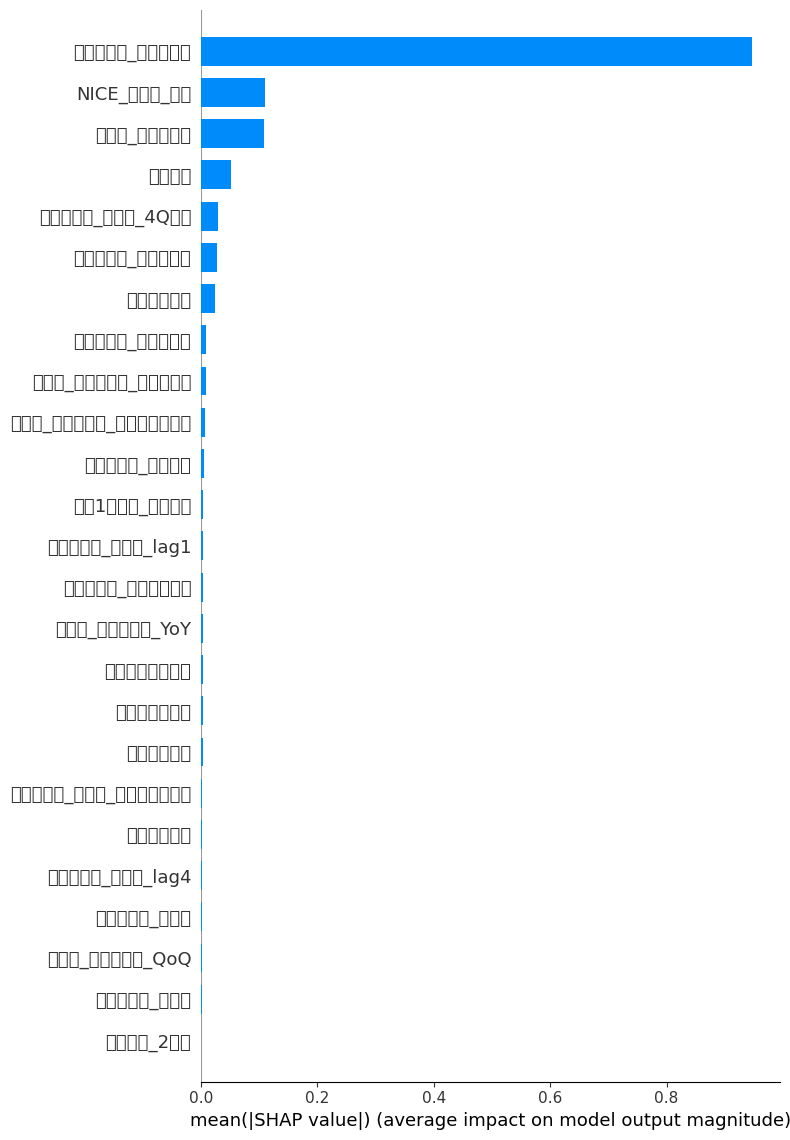

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\Ap

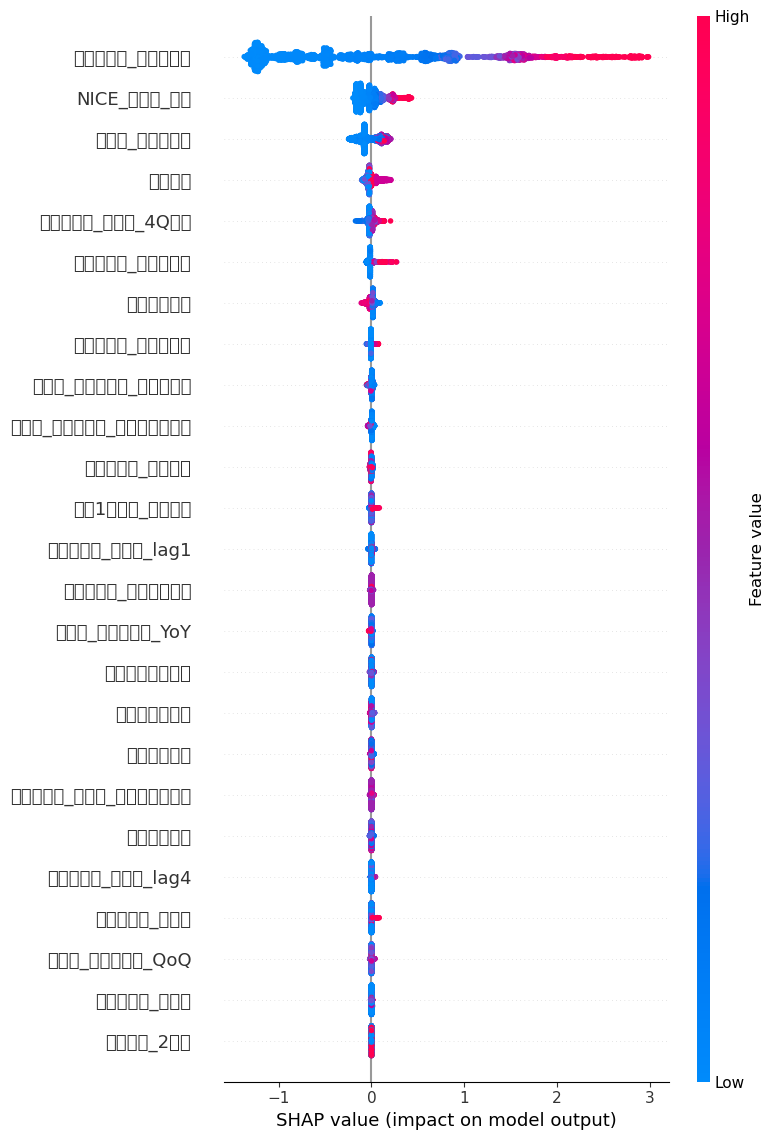


SHAP 중요도 저장 완료


In [9]:
# =========================================================
# SHAP 분석
# =========================================================

# 설치가 안 되어 있다면 최초 1회
# !pip install shap

import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# 1. SHAP Explainer 생성
# =========================================================

explainer = shap.TreeExplainer(model)


# =========================================================
# 2. SHAP 값 계산
# =========================================================
# 현재 학습 데이터 전체를 기준으로 전역 중요도 계산

shap_values = explainer.shap_values(X_train)

print("SHAP 값 shape:", np.array(shap_values).shape)
print("X_train shape :", X_train.shape)


# =========================================================
# 3. 변수별 mean(|SHAP|) 계산
# =========================================================
# 각 변수의 SHAP 절댓값을 모든 관측치에 대해 평균
# → 값이 클수록 모델 예측에 평균적으로 큰 영향을 준 변수

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean_ABS_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values("Mean_ABS_SHAP", ascending=False)
    .reset_index(drop=True)
)


# =========================================================
# 4. 상대적 중요도(%) 계산
# =========================================================

shap_importance_df["Importance_pct"] = (
    shap_importance_df["Mean_ABS_SHAP"]
    / shap_importance_df["Mean_ABS_SHAP"].sum()
    * 100
)

# 누적 중요도
shap_importance_df["Cumulative_pct"] = (
    shap_importance_df["Importance_pct"].cumsum()
)


print("\n==========================================")
print(" SHAP Feature Importance")
print("==========================================")

print(
    shap_importance_df.to_string(
        index=False,
        formatters={
            "Mean_ABS_SHAP": "{:.6f}".format,
            "Importance_pct": "{:.2f}".format,
            "Cumulative_pct": "{:.2f}".format
        }
    )
)


# =========================================================
# 5. SHAP 중요도 Bar Plot
# =========================================================

shap.summary_plot(
    shap_values,
    X_train,
    plot_type="bar",
    max_display=len(features),
    show=True
)


# =========================================================
# 6. SHAP Summary Plot
# =========================================================
# 변수의 중요도뿐만 아니라
# 변수 값이 높고/낮을 때 예측값에 어떤 영향을 주는지도 확인

shap.summary_plot(
    shap_values,
    X_train,
    max_display=len(features),
    show=True
)


# =========================================================
# 7. SHAP 중요도 CSV 저장
# =========================================================

shap_importance_df.to_csv(
    "Poisson_SHAP_FeatureImportance.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nSHAP 중요도 저장 완료")

### 변수 상관관계

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 학습 데이터의 설명변수만 사용
corr = X_train.corr(method="pearson")

# 절대 상관계수
abs_corr = corr.abs()

# 자기 자신 및 중복 조합 제거
upper = abs_corr.where(
    np.triu(
        np.ones(abs_corr.shape),
        k=1
    ).astype(bool)
)

# |r| >= 0.7인 변수 조합
high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Abs_Correlation"
]

high_corr_pairs = (
    high_corr_pairs[
        high_corr_pairs["Abs_Correlation"] >= 0.7
    ]
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print(high_corr_pairs.to_string(index=False))

      Feature_1         Feature_2  Abs_Correlation
       업태구분_2진수        읍면동업태_점포비중         0.973158
    읍면동업태_영업점포수       NICE_총매출_만원         0.945945
         평균시설규모            중앙시설규모         0.929095
    읍면동업태_분기개업수       읍면동업태_분기폐업수         0.912708
    읍면동업태_분기폐업수       NICE_총매출_만원         0.867345
    읍면동업태_영업점포수       읍면동업태_분기폐업수         0.860039
    읍면동업태_분기개업수       NICE_총매출_만원         0.851437
      읍면동업태_개업률      읍면동업태_점포수증감률         0.824193
    읍면동업태_영업점포수       읍면동업태_분기개업수         0.811757
법정동_인구천명당_전체점포수 법정동_인구천명당_동일업태점포수         0.744246
      읍면동업태_폐업률 읍면동업태_폐업률_전분기대비증감         0.711246


### 변수 12 vs 변수 26개 검증

In [15]:
# =========================================================
# 전체모델 Feature Set
# 직전분기말점포수 제거
# 총매출 대신 점포당_매출_log 사용
# =========================================================

features_all = [
    # 계절·업태
    "분기번호",
    "업태구분_2진수",

    # 점포 규모
    "읍면동업태_영업점포수",

    # 점포 구성
    "평균업력개월",
    "업력1년미만_점포비중",
    "평균시설규모",
    "중앙시설규모",
    "소규모점포비중",
    "다중이용업소비중",

    # 지역 수요·경쟁
    "법정동_실제총인구",
    "법정동_인구증감률_QoQ",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_전체점포수",
    "법정동_인구천명당_동일업태점포수",

    # 현재 상권 상태
    "읍면동업태_분기개업수",
    "읍면동업태_분기폐업수",
    "읍면동업태_점포비중",
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_점포수증감률",

    # 과거 폐업 추세
    "읍면동업태_폐업률_lag1",
    "읍면동업태_폐업률_lag4",
    "읍면동업태_폐업률_4Q평균",
    "읍면동업태_폐업률_전분기대비증감",

    # 매출
    "점포당_매출_log"
]


# =========================================================
# 축소모델 Feature Set
# =========================================================

features_12 = [
    # 계절·업태
    "분기번호",
    "업태구분_2진수",

    # 점포 규모
    "읍면동업태_영업점포수",

    # 점포 구성
    "평균업력개월",
    "업력1년미만_점포비중",

    # 지역 수요·경쟁
    "법정동_실제총인구",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_동일업태점포수",

    # 현재 상권 상태·과거 폐업 추세
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_폐업률_4Q평균",

    # 매출
    "점포당_매출_log"
]


print("전체모델 변수 수:", len(features_all))
print("축소모델 변수 수:", len(features_12))

target = "다음분기_폐업수"


# =========================================================
# 2. 2026년은 완전히 제외
# =========================================================

cv_df = df[df["기준연도"] <= 2025].copy()

print("CV 사용 데이터:", cv_df.shape)
print("2026 포함 여부:", (cv_df["기준연도"] == 2026).any())


# =========================================================
# 3. Expanding-window CV 설정
# =========================================================
# 최소 4개 분기를 학습한 뒤 다음 분기 검증
#
# 2023Q1~Q4 -> 2024Q1
# 2023Q1~2024Q1 -> 2024Q2
# ...
# 2023Q1~2025Q3 -> 2025Q4
# =========================================================

valid_quarters = [
    "2024Q1", "2024Q2", "2024Q3", "2024Q4",
    "2025Q1", "2025Q2", "2025Q3", "2025Q4"
]


# =========================================================
# 4. 모델 함수
# =========================================================

def make_model():
    return lgb.LGBMRegressor(
        objective="poisson",
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=30,
        reg_alpha=0.1,
        reg_lambda=1.0,
        colsample_bytree=0.9,
        subsample=0.9,
        max_depth=-1,
        n_estimators=120,
        random_state=42,
        verbosity=-1,
        force_col_wise=True,
        n_jobs=4
    )


# =========================================================
# 5. CV 함수
# =========================================================

def expanding_cv(data, feature_list, model_name):

    results = []

    quarter_order = sorted(
        data["기준분기"].unique(),
        key=lambda x: (int(x[:4]), int(x[-1]))
    )

    for valid_q in valid_quarters:

        valid_idx = quarter_order.index(valid_q)
        train_quarters = quarter_order[:valid_idx]

        train_fold = data[
            data["기준분기"].isin(train_quarters)
        ].copy()

        valid_fold = data[
            data["기준분기"] == valid_q
        ].copy()

        X_train = train_fold[feature_list]
        y_train = train_fold[target]

        X_valid = valid_fold[feature_list]
        y_valid = valid_fold[target]

        model = make_model()

        # sample_weight 없이 동일 조건 비교
        model.fit(X_train, y_train)

        pred = model.predict(X_valid)
        pred = np.clip(pred, 0, None)

        mae = mean_absolute_error(y_valid, pred)
        rmse = np.sqrt(mean_squared_error(y_valid, pred))
        r2 = r2_score(y_valid, pred)

        # 상수 등의 예외 방지
        try:
            pearson = pearsonr(y_valid, pred)[0]
        except:
            pearson = np.nan

        try:
            spearman = spearmanr(y_valid, pred)[0]
        except:
            spearman = np.nan

        results.append({
            "Model": model_name,
            "Valid_Quarter": valid_q,
            "Train_Start": train_quarters[0],
            "Train_End": train_quarters[-1],
            "Train_N": len(train_fold),
            "Valid_N": len(valid_fold),
            "Feature_N": len(feature_list),

            "MAE": mae,
            "RMSE": rmse,
            "Pearson": pearson,
            "Spearman": spearman,
            "R2": r2
        })

    return pd.DataFrame(results)


# =========================================================
# 6. 전체모델 vs 12개 모델
# =========================================================

cv_all = expanding_cv(
    cv_df,
    features_all,
    "전체모델"
)

cv_12 = expanding_cv(
    cv_df,
    features_12,
    "축소모델_12"
)

cv_result = pd.concat(
    [cv_all, cv_12],
    ignore_index=True
)


# =========================================================
# 7. 분기별 결과
# =========================================================

print("\n" + "=" * 90)
print("분기별 CV 결과")
print("=" * 90)

print(
    cv_result[
        [
            "Model",
            "Valid_Quarter",
            "Feature_N",
            "MAE",
            "RMSE",
            "Pearson",
            "Spearman",
            "R2"
        ]
    ].round(4).to_string(index=False)
)


# =========================================================
# 8. 평균 성능 비교
# =========================================================

summary = (
    cv_result
    .groupby("Model")
    .agg(
        Feature_N=("Feature_N", "first"),

        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),

        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),

        Pearson_mean=("Pearson", "mean"),
        Spearman_mean=("Spearman", "mean"),

        R2_mean=("R2", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 90)
print("전체모델 vs 12개 축소모델 - Expanding Window CV 평균")
print("=" * 90)

print(
    summary.round(4).to_string(index=False)
)


# =========================================================
# 9. 축소모델이 얼마나 변했는지 계산
# =========================================================

all_row = summary[
    summary["Model"] == "전체모델"
].iloc[0]

small_row = summary[
    summary["Model"] == "축소모델_12"
].iloc[0]

mae_change = (
    (small_row["MAE_mean"] - all_row["MAE_mean"])
    / all_row["MAE_mean"] * 100
)

rmse_change = (
    (small_row["RMSE_mean"] - all_row["RMSE_mean"])
    / all_row["RMSE_mean"] * 100
)

print("\n" + "=" * 90)
print("축소에 따른 성능 변화")
print("=" * 90)

print(f"MAE 변화율  : {mae_change:+.2f}%")
print(f"RMSE 변화율 : {rmse_change:+.2f}%")


# =========================================================
# 10. 저장
# =========================================================

cv_result.to_csv(
    "전체25_vs_축소12_ExpandingCV_분기별.csv",
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    "전체25_vs_축소12_ExpandingCV_평균.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n저장 완료")

전체모델 변수 수: 25
축소모델 변수 수: 12
CV 사용 데이터: (3120, 47)
2026 포함 여부: False

분기별 CV 결과
  Model Valid_Quarter  Feature_N    MAE   RMSE  Pearson  Spearman     R2
   전체모델        2024Q1         25 1.4215 2.8641   0.9478    0.8173 0.8962
   전체모델        2024Q2         25 1.2946 2.4806   0.9582    0.8337 0.8862
   전체모델        2024Q3         25 2.5817 6.1373   0.9540    0.8728 0.7940
   전체모델        2024Q4         25 1.3762 2.8548   0.9418    0.8186 0.8867
   전체모델        2025Q1         25 1.4921 2.9682   0.9445    0.8114 0.8765
   전체모델        2025Q2         25 1.2168 2.0068   0.9662    0.8103 0.9315
   전체모델        2025Q3         25 1.8034 3.6629   0.9605    0.8726 0.8995
   전체모델        2025Q4         25 1.4445 2.5377   0.9475    0.8160 0.8940
축소모델_12        2024Q1         12 1.4047 2.8762   0.9518    0.8207 0.8953
축소모델_12        2024Q2         12 1.2412 2.2890   0.9619    0.8336 0.9031
축소모델_12        2024Q3         12 2.6933 6.6448   0.9593    0.8717 0.7586
축소모델_12        2024Q4         12 1.3890 3.045

AttributeError: module 'matplotlib' has no attribute 'backends'

### offset-Poisson LightGBM

① 데이터 준비 → ② Offset 설정 → ③ 시간순 CV → ④ 최종학습 → ⑤ 2026년 평가 → ⑥ SHAP 분석 → ⑦ 결과 저장

전체 데이터: (3642, 45)
기준분기
2023Q1    259
2023Q2    259
2023Q3    259
2023Q4    260
2024Q1    260
2024Q2    260
2024Q3    259
2024Q4    260
2025Q1    261
2025Q2    261
2025Q3    261
2025Q4    261
2026Q1    261
2026Q2    261
Name: count, dtype: int64
Offset 생성 완료
Feature 수: 11
Features: ['분기번호', '업태구분_2진수', '평균업력개월', '업력1년미만_점포비중', '법정동_실제총인구', '법정동_인구증감률_YoY', '법정동_인구천명당_동일업태점포수', '읍면동업태_개업률', '읍면동업태_폐업률', '읍면동업태_폐업률_4Q평균', '점포당_매출_log']

Train: (3120, 48)
Test : (522, 48)

Fold1
Train: 1557
Valid: 519
MAE : 6.5062
RMSE: 14.9790
총량비: 2.2988

Fold2
Train: 2076
Valid: 522
MAE : 7.5036
RMSE: 17.0482
총량비: 3.1896

Fold3
Train: 2598
Valid: 522
MAE : 6.8717
RMSE: 16.0144
총량비: 2.5377

CV 결과
   Count_MAE  Count_RMSE  Count_R2  Count_Pearson  Count_Spearman  \
0     6.5062     14.9790   -0.7449         0.9269          0.8424   
1     7.5036     17.0482   -3.4641         0.9359          0.8176   
2     6.8717     16.0144   -1.6201         0.9424          0.8407   

   Poisson_Deviance  Rate_MAE  Rate

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3790959054.py:1046: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3790959054.py:1046: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3790959054.py:1046: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3790959054.py:1046: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3790959054.py:1046: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416

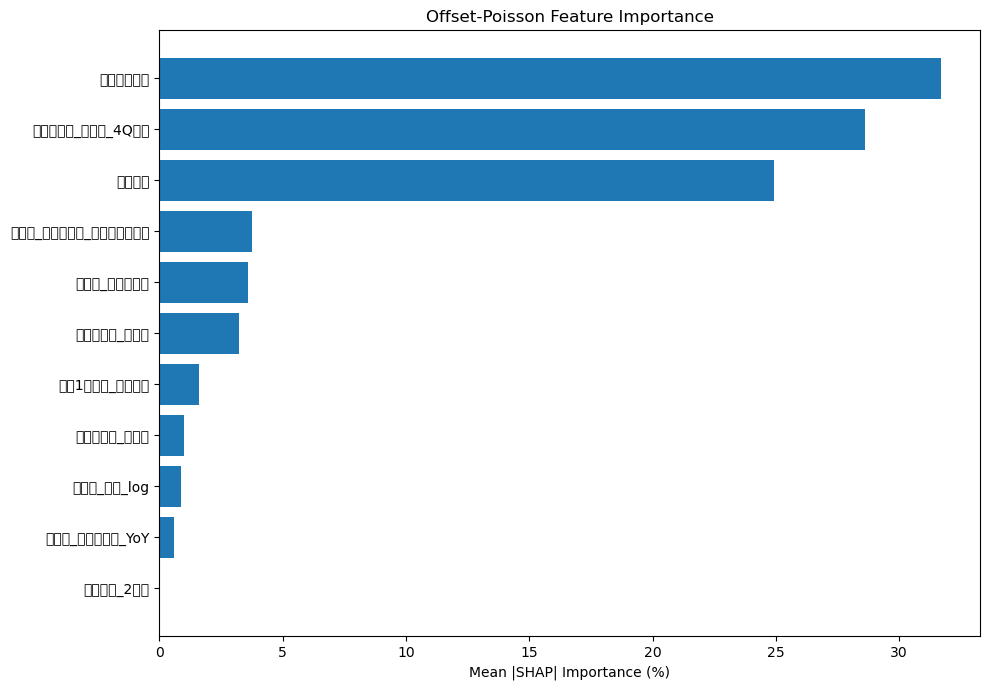

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 50629 (\N{HANGUL SYLLABLE EOB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Roaming\Python\Python313\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\Ap

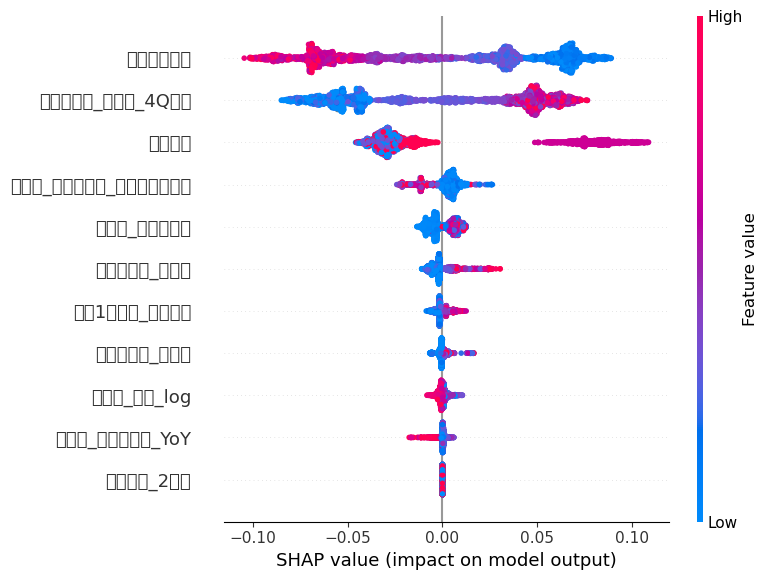


모든 분석 완료
저장 폴더: C:\Users\user\Desktop\AI경진대회\lightGBM\Offset_Poisson_Results


In [5]:
# ============================================================
# Offset-Poisson LightGBM
# 다음분기 폐업수 예측
#
# Train : 2023Q1 ~ 2025Q4
# Test  : 2026Q1 ~ 2026Q2
#
# 관측단위 : 분기 × 읍면동 × 업태
# Target : 다음분기_폐업수
# Offset : log(읍면동업태_영업점포수)
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

from scipy.stats import pearsonr, spearmanr


# =========================================================
# 1. 데이터 불러오기
# =========================================================

file_path = (
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리\[채택][새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv"
)

df = pd.read_csv(file_path)

print("전체 데이터:", df.shape)
print(df["기준분기"].value_counts().sort_index())

OUTPUT_DIR = Path("Offset_Poisson_Results")
OUTPUT_DIR.mkdir(exist_ok=True)


# ------------------------------------------------------------
# 1-1. 매출 변수
# ------------------------------------------------------------

# 기존에 점포당_매출_log가 만들어져 있다면 그대로 사용

if "점포당_매출_log" not in df.columns:

    df["점포당_매출"] = (
        df["NICE_총매출_만원"]
        / df["읍면동업태_영업점포수"].replace(0, np.nan)
    )

    df["점포당_매출_log"] = np.log1p(
        df["점포당_매출"]
    )


# ------------------------------------------------------------
# 1-2. 영업점포수 확인
# ------------------------------------------------------------

exposure_col = "읍면동업태_영업점포수"

df[exposure_col] = pd.to_numeric(
    df[exposure_col],
    errors="coerce"
)

# 현재 데이터는 영업점포수가 1 이상인 행을 관측단위로 사용
# 0 또는 결측인 경우 Offset 정의가 불가능하므로 확인

invalid_exposure = (
    df[exposure_col].isna()
    | (df[exposure_col] <= 0)
)

if invalid_exposure.any():
    raise ValueError(
        f"영업점포수가 0 이하이거나 결측인 행이 "
        f"{invalid_exposure.sum()}개 있습니다."
    )


# ------------------------------------------------------------
# 1-3. Offset 생성
# ------------------------------------------------------------

df["offset_log"] = np.log(
    df[exposure_col]
)

print("Offset 생성 완료")


# ============================================================
# 2. Feature 설정
# ============================================================

# 영업점포수는 Offset으로 처리하므로
# 일반 Feature에서는 제외

features_offset = [

    # 계절·업태
    "분기번호",
    "업태구분_2진수",

    # 점포 구성
    "평균업력개월",
    "업력1년미만_점포비중",

    # 지역 수요·경쟁
    "법정동_실제총인구",
    "법정동_인구증감률_YoY",
    "법정동_인구천명당_동일업태점포수",

    # 상권 상태
    "읍면동업태_개업률",
    "읍면동업태_폐업률",
    "읍면동업태_폐업률_4Q평균",

    # 매출
    "점포당_매출_log"
]


target_count = "다음분기_폐업수"
target_rate = "다음분기_폐업률"


print("Feature 수:", len(features_offset))
print("Features:", features_offset)


# ------------------------------------------------------------
# 2-1. 필수 컬럼 확인
# ------------------------------------------------------------

required_cols = (
    features_offset
    + [
        target_count,
        target_rate,
        exposure_col,
        "offset_log",
        "기준연도",
        "기준분기"
    ]
)

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

if missing_cols:
    raise ValueError(
        f"누락된 컬럼: {missing_cols}"
    )


# ------------------------------------------------------------
# 2-2. 숫자형 변환
# ------------------------------------------------------------

for col in features_offset:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

    df[col] = df[col].replace(
        [np.inf, -np.inf],
        np.nan
    )


# NaN은 LightGBM이 처리하므로 유지


# ============================================================
# 3. 모델 설정
# ============================================================

MODEL_PARAMS = dict(

    objective="poisson",

    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=30,

    reg_alpha=0.1,
    reg_lambda=1.0,

    colsample_bytree=0.9,
    subsample=0.9,

    max_depth=-1,
    n_estimators=120,

    random_state=42,

    verbosity=-1,
    force_col_wise=True,
    n_jobs=4

)


# ============================================================
# 4. Offset 모델 학습 함수
# ============================================================

def fit_offset_model(train_data):

    X = train_data[features_offset]

    y = train_data[target_count].astype(float)

    offset_train = train_data[
        "offset_log"
    ].to_numpy(dtype=float)

    model = lgb.LGBMRegressor(
        **MODEL_PARAMS
    )

    # init_score는 Poisson log-link의 초기 raw score
    # 학습 시 각 행의 log(영업점포수)를 제공

    model.fit(
        X,
        y,
        init_score=offset_train
    )

    return model


# ============================================================
# 5. Offset 예측 함수
# ============================================================

def predict_offset_model(model, data):

    X = data[features_offset]

    offset = data[
        "offset_log"
    ].to_numpy(dtype=float)

    # LightGBM 트리의 raw score
    # init_score는 예측 시 자동으로 더해지지 않으므로
    # 예측 대상 행의 Offset을 직접 더함

    raw_pred = model.predict(
        X,
        raw_score=True
    )

    # Poisson log-link 복원
    #
    # log(예측폐업수)
    # = log(영업점포수) + 모델의 보정값

    pred_count = np.exp(
        np.clip(raw_pred + offset, -30, 30)
    )

    # 폐업률 환산
    # 반드시 원래 영업점포수 사용

    pred_rate = (
        pred_count
        / data[exposure_col].to_numpy(dtype=float)
    )

    pred_rate = np.clip(
        pred_rate,
        0,
        1
    )

    return pred_count, pred_rate


# ============================================================
# 6. 평가 함수
# ============================================================

def evaluate_model(
    actual_count,
    pred_count,
    actual_rate,
    pred_rate
):

    actual_count = np.asarray(
        actual_count,
        dtype=float
    )

    pred_count = np.asarray(
        pred_count,
        dtype=float
    )

    actual_rate = np.asarray(
        actual_rate,
        dtype=float
    )

    pred_rate = np.asarray(
        pred_rate,
        dtype=float
    )

    # --------------------------------------------------------
    # 폐업수
    # --------------------------------------------------------

    count_mae = mean_absolute_error(
        actual_count,
        pred_count
    )

    count_rmse = np.sqrt(
        mean_squared_error(
            actual_count,
            pred_count
        )
    )

    count_r2 = r2_score(
        actual_count,
        pred_count
    )

    count_pearson = pearsonr(
        actual_count,
        pred_count
    )[0]

    count_spearman = spearmanr(
        actual_count,
        pred_count
    )[0]

    poisson_deviance = mean_poisson_deviance(
        actual_count,
        np.maximum(pred_count, 1e-10)
    )

    # --------------------------------------------------------
    # 폐업률
    # --------------------------------------------------------

    rate_mae = mean_absolute_error(
        actual_rate,
        pred_rate
    )

    rate_rmse = np.sqrt(
        mean_squared_error(
            actual_rate,
            pred_rate
        )
    )

    rate_r2 = r2_score(
        actual_rate,
        pred_rate
    )

    # --------------------------------------------------------
    # 총량비
    # --------------------------------------------------------

    actual_total = actual_count.sum()
    pred_total = pred_count.sum()

    total_ratio = (
        pred_total / actual_total
        if actual_total > 0
        else np.nan
    )

    return {

        "Count_MAE": count_mae,
        "Count_RMSE": count_rmse,
        "Count_R2": count_r2,
        "Count_Pearson": count_pearson,
        "Count_Spearman": count_spearman,

        "Poisson_Deviance": poisson_deviance,

        "Rate_MAE": rate_mae,
        "Rate_RMSE": rate_rmse,
        "Rate_R2": rate_r2,

        "Actual_Total": actual_total,
        "Pred_Total": pred_total,
        "Total_Ratio": total_ratio

    }


# ============================================================
# 7. Train / Test 분리
# ============================================================

train_df = df[
    df["기준연도"] <= 2025
].copy()

test_df = df[
    df["기준연도"] == 2026
].copy()


print("\nTrain:", train_df.shape)
print("Test :", test_df.shape)


# ============================================================
# 8. Expanding Window CV
#
# Fold 1
# Train : 2023Q1 ~ 2024Q2
# Valid : 2024Q3 ~ 2024Q4
#
# Fold 2
# Train : 2023Q1 ~ 2024Q4
# Valid : 2025Q1 ~ 2025Q2
#
# Fold 3
# Train : 2023Q1 ~ 2025Q2
# Valid : 2025Q3 ~ 2025Q4
# ============================================================

cv_folds = [

    (
        "Fold1",
        "2024Q2",
        ["2024Q3", "2024Q4"]
    ),

    (
        "Fold2",
        "2024Q4",
        ["2025Q1", "2025Q2"]
    ),

    (
        "Fold3",
        "2025Q2",
        ["2025Q3", "2025Q4"]
    )

]


# 분기 비교를 위한 숫자 변환

df["quarter_order"] = (
    df["기준연도"].astype(int) * 4
    + df["분기번호"].astype(int)
)

train_df["quarter_order"] = (
    train_df["기준연도"].astype(int) * 4
    + train_df["분기번호"].astype(int)
)


def quarter_to_order(q):

    year = int(q[:4])
    quarter = int(q[-1])

    return year * 4 + quarter


cv_results = []
cv_predictions = []


# ============================================================
# 9. CV 실행
# ============================================================

for fold_name, train_end, valid_quarters in cv_folds:

    train_end_order = quarter_to_order(
        train_end
    )

    fold_train = train_df[
        train_df["quarter_order"] <= train_end_order
    ].copy()

    fold_valid = train_df[
        train_df["기준분기"].isin(valid_quarters)
    ].copy()

    print("\n" + "=" * 60)
    print(f"{fold_name}")
    print("=" * 60)

    print("Train:", len(fold_train))
    print("Valid:", len(fold_valid))

    # --------------------------------------------------------
    # 학습
    # --------------------------------------------------------

    fold_model = fit_offset_model(
        fold_train
    )

    # --------------------------------------------------------
    # 예측
    # --------------------------------------------------------

    pred_count, pred_rate = predict_offset_model(
        fold_model,
        fold_valid
    )

    # --------------------------------------------------------
    # 평가
    # --------------------------------------------------------

    metrics = evaluate_model(

        fold_valid[target_count],
        pred_count,

        fold_valid[target_rate],
        pred_rate

    )

    metrics["Fold"] = fold_name

    cv_results.append(metrics)

    # --------------------------------------------------------
    # 예측 결과 저장
    # --------------------------------------------------------

    temp = fold_valid[
        [
            "기준분기",
            "군구명_개편후",
            "읍면동_개편후",
            "업태구분명",
            exposure_col,
            target_count,
            target_rate
        ]
    ].copy()

    temp["Fold"] = fold_name

    temp["예측_폐업수"] = pred_count
    temp["예측_폐업률"] = pred_rate

    cv_predictions.append(temp)

    print(
        f"MAE : {metrics['Count_MAE']:.4f}"
    )

    print(
        f"RMSE: {metrics['Count_RMSE']:.4f}"
    )

    print(
        f"총량비: {metrics['Total_Ratio']:.4f}"
    )


# ============================================================
# 10. CV 결과 정리
# ============================================================

cv_results_df = pd.DataFrame(
    cv_results
)

cv_predictions_df = pd.concat(
    cv_predictions,
    ignore_index=True
)


print("\n" + "=" * 60)
print("CV 결과")
print("=" * 60)

print(
    cv_results_df.round(4)
)


# ------------------------------------------------------------
# 10-1. Fold 평균
# ------------------------------------------------------------

cv_mean = (
    cv_results_df
    .drop(columns=["Fold"])
    .mean(numeric_only=True)
)

print("\nCV Fold 평균")

print(
    cv_mean.round(4)
)


# ------------------------------------------------------------
# 10-2. 전체 OOF 평가
# ------------------------------------------------------------

# 각 Fold의 검증 예측을 합쳐서 평가

oof_metrics = evaluate_model(

    cv_predictions_df[target_count],
    cv_predictions_df["예측_폐업수"],

    cv_predictions_df[target_rate],
    cv_predictions_df["예측_폐업률"]

)

print("\nCV 전체 OOF 성능")

print(
    pd.Series(oof_metrics).round(4)
)


# ------------------------------------------------------------
# 10-3. 저장
# ------------------------------------------------------------

cv_results_df.to_csv(
    OUTPUT_DIR / "Offset_CV_Fold별_성능.csv",
    index=False,
    encoding="utf-8-sig"
)

cv_predictions_df.to_csv(
    OUTPUT_DIR / "Offset_CV_예측결과.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.Series(oof_metrics).to_csv(
    OUTPUT_DIR / "Offset_CV_OOF_성능.csv",
    encoding="utf-8-sig"
)


# ============================================================
# 11. 최종 모델 학습
#
# 2023Q1 ~ 2025Q4 전체 사용
# ============================================================

final_model = fit_offset_model(
    train_df
)

print("\n최종 모델 학습 완료")


# ============================================================
# 12. 2026Q1 ~ 2026Q2 최종 평가
#
# 주의:
# 실제 모델 선택은 앞선 CV에서 완료해야 함
# ============================================================

final_pred_count, final_pred_rate = (
    predict_offset_model(
        final_model,
        test_df
    )
)


test_metrics = evaluate_model(

    test_df[target_count],
    final_pred_count,

    test_df[target_rate],
    final_pred_rate

)


print("\n" + "=" * 60)
print("2026 최종 Test 성능")
print("=" * 60)

for metric, value in test_metrics.items():

    print(
        f"{metric:20s}: {value:.6f}"
    )


# ============================================================
# 13. 점포 규모별 성능
# ============================================================

result_df = test_df[
    [
        "기준분기",
        "군구명_개편후",
        "읍면동_개편후",
        "업태구분명",
        exposure_col,
        target_count,
        target_rate
    ]
].copy()


result_df["예측_폐업수"] = final_pred_count
result_df["예측_폐업률"] = final_pred_rate


# ------------------------------------------------------------
# 규모 구간
# ------------------------------------------------------------

result_df["점포규모구간"] = pd.cut(

    result_df[exposure_col],

    bins=[
        0,
        30,
        100,
        300,
        np.inf
    ],

    labels=[
        "30개 이하",
        "31~100개",
        "101~300개",
        "300개 초과"
    ]

)


# ------------------------------------------------------------
# 규모별 MAE
# ------------------------------------------------------------

size_results = []

for size_group, group in result_df.groupby(
    "점포규모구간",
    observed=True
):

    mae = mean_absolute_error(

        group[target_count],
        group["예측_폐업수"]

    )

    rmse = np.sqrt(
        mean_squared_error(

            group[target_count],
            group["예측_폐업수"]

        )
    )

    size_results.append({

        "점포규모구간": size_group,
        "행수": len(group),

        "실제평균폐업수": group[target_count].mean(),
        "예측평균폐업수": group["예측_폐업수"].mean(),

        "MAE": mae,
        "RMSE": rmse

    })


size_results_df = pd.DataFrame(
    size_results
)


print("\n점포 규모별 성능")

print(
    size_results_df.round(4)
)


# ============================================================
# 14. 업태별 성능
# ============================================================

industry_results = []

for industry, group in result_df.groupby(
    "업태구분명"
):

    industry_results.append({

        "업태": industry,

        "행수": len(group),

        "MAE": mean_absolute_error(
            group[target_count],
            group["예측_폐업수"]
        ),

        "RMSE": np.sqrt(
            mean_squared_error(
                group[target_count],
                group["예측_폐업수"]
            )
        ),

        "실제폐업수합계": group[target_count].sum(),

        "예측폐업수합계": group["예측_폐업수"].sum()

    })


industry_results_df = pd.DataFrame(
    industry_results
)


print("\n업태별 성능")

print(
    industry_results_df.round(4)
)


# ============================================================
# 15. SHAP 분석
#
# 중요:
# Offset은 SHAP 분석 대상 Feature가 아님
#
# SHAP은 LightGBM이 학습한
# log(폐업위험) 보정값에 대한 기여도를 설명
# ============================================================

X_train = train_df[
    features_offset
].copy()


# LightGBM 자체 SHAP contribution
# 마지막 열은 expected value

shap_contrib = final_model.predict(

    X_train,

    pred_contrib=True

)


shap_values = shap_contrib[:, :-1]

expected_value = shap_contrib[:, -1]


# ------------------------------------------------------------
# 15-1. SHAP 계산 검증
# ------------------------------------------------------------

raw_pred = final_model.predict(

    X_train,

    raw_score=True

)


reconstructed_raw = (
    shap_values.sum(axis=1)
    + expected_value
)


max_difference = np.max(
    np.abs(
        raw_pred - reconstructed_raw
    )
)


print("\nSHAP 가산성 검증")

print(
    f"최대 오차: {max_difference:.10f}"
)

assert np.allclose(
    raw_pred,
    reconstructed_raw,
    atol=1e-5
), "SHAP 합계와 모델 raw score가 일치하지 않습니다."


# ------------------------------------------------------------
# 15-2. SHAP 중요도
# ------------------------------------------------------------

mean_abs_shap = np.abs(
    shap_values
).mean(axis=0)


shap_importance_df = pd.DataFrame({

    "Feature": features_offset,

    "Mean_ABS_SHAP": mean_abs_shap

})


shap_importance_df = (

    shap_importance_df

    .sort_values(
        "Mean_ABS_SHAP",
        ascending=False
    )

    .reset_index(drop=True)

)


shap_total = shap_importance_df[
    "Mean_ABS_SHAP"
].sum()


shap_importance_df["Importance_pct"] = (

    shap_importance_df["Mean_ABS_SHAP"]
    / shap_total
    * 100

)


shap_importance_df["Cumulative_pct"] = (

    shap_importance_df[
        "Importance_pct"
    ].cumsum()

)


print("\n" + "=" * 60)
print("Offset-Poisson SHAP 중요도")
print("=" * 60)

print(
    shap_importance_df.round(4)
)


# ============================================================
# 16. SHAP 시각화
# ============================================================

# ------------------------------------------------------------
# 16-1. SHAP 중요도 Bar
# ------------------------------------------------------------

plot_df = shap_importance_df.sort_values(
    "Importance_pct",
    ascending=True
)


plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_pct"]
)

plt.xlabel(
    "Mean |SHAP| Importance (%)"
)

plt.title(
    "Offset-Poisson Feature Importance"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Offset_SHAP_Bar.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 16-2. SHAP Beeswarm
# ------------------------------------------------------------

import shap

shap.summary_plot(

    shap_values,

    X_train,

    show=False

)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Offset_SHAP_Beeswarm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. 결과 저장
# ============================================================

result_df.to_csv(

    OUTPUT_DIR / "Offset_2026_예측결과.csv",

    index=False,
    encoding="utf-8-sig"

)


size_results_df.to_csv(

    OUTPUT_DIR / "Offset_점포규모별_성능.csv",

    index=False,
    encoding="utf-8-sig"

)


industry_results_df.to_csv(

    OUTPUT_DIR / "Offset_업태별_성능.csv",

    index=False,
    encoding="utf-8-sig"

)


shap_importance_df.to_csv(

    OUTPUT_DIR / "Offset_SHAP_중요도.csv",

    index=False,
    encoding="utf-8-sig"

)


pd.Series(test_metrics).to_csv(

    OUTPUT_DIR / "Offset_2026_최종성능.csv",

    encoding="utf-8-sig"

)


# ------------------------------------------------------------
# 17-1. 모델 저장
# ------------------------------------------------------------

final_model.booster_.save_model(

    str(
        OUTPUT_DIR / "Offset_Poisson_Final_Model.txt"
    )

)


print("\n" + "=" * 60)
print("모든 분석 완료")
print("=" * 60)

print("저장 폴더:", OUTPUT_DIR.resolve())

### 일반 possion(영업점포수 변수 예측인자에 포함) vs offset

In [6]:
# ============================================================
# 일반 Poisson vs Offset Poisson 공정 비교 (다음분기_폐업수)
#  - 시계열 CV(2023~2025)로만 모델 선택
#  - 2026 Test는 RUN_TEST=True 로 바꿀 때만 평가 (봉인)
# ============================================================
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
from pathlib import Path

# ---------------- 설정 ----------------
FILE_PATH = os.environ.get(
    "DATA_PATH",
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리\[채택][새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv",
)
RUN_TEST = os.environ.get("RUN_TEST", "0") == "1"   # CV로 모델 확정 후에만 1
FINAL_MODEL = "B"                                   # "A"=일반 Poisson, "B"=Offset Poisson (CV 결과 보고 확정)
OUT = Path("Poisson_Compare_Results"); OUT.mkdir(exist_ok=True)

N, Y, YR = "읍면동업태_영업점포수", "다음분기_폐업수", "다음분기_폐업률"

# 두 모델이 공유하는 변수 (영업점포수 제외)
BASE = [
    "분기번호", "업태구분_2진수",
    "평균업력개월", "업력1년미만_점포비중",
    "법정동_실제총인구", "법정동_인구증감률_YoY", "법정동_인구천명당_동일업태점포수",
    "읍면동업태_개업률", "읍면동업태_폐업률", "읍면동업태_폐업률_4Q평균",
    "점포당_매출_log",
]
FEATS = {"A": BASE + [N],   # 일반: 점포수를 변수로 사용
         "B": BASE}         # 오프셋: 점포수는 offset으로만 사용

PARAMS = dict(objective="poisson", learning_rate=0.05, num_leaves=15,
              min_child_samples=30, reg_alpha=0.1, reg_lambda=1.0,
              colsample_bytree=0.9, subsample=0.9, subsample_freq=1,
              n_estimators=200, random_state=42, verbosity=-1,
              force_col_wise=True, n_jobs=4)

# 시간순 CV: (학습 마지막 분기, 검증 분기들)
FOLDS = [("Fold1", "2024Q2", ["2024Q3", "2024Q4"]),
         ("Fold2", "2024Q4", ["2025Q1", "2025Q2"]),
         ("Fold3", "2025Q2", ["2025Q3", "2025Q4"])]

# ---------------- 데이터 ----------------
df = pd.read_csv(FILE_PATH)
df[N] = pd.to_numeric(df[N], errors="coerce")
assert (df[N] > 0).all(), "영업점포수가 0 이하/결측인 행이 있습니다."

df["점포당_매출_log"] = np.log1p(df["NICE_총매출_만원"] / df[N])
for c in set(BASE + [N]):
    df[c] = pd.to_numeric(df[c], errors="coerce").replace([np.inf, -np.inf], np.nan)  # NaN은 LightGBM이 처리

dev = df[df["기준연도"] <= 2025].copy()
test = df[df["기준연도"] == 2026].copy()
print("Train/Dev:", dev.shape, "| Test:", test.shape)


# ---------------- 학습/예측 ----------------
def fit_predict(kind, tr, te):
    """kind: 'A' 일반 Poisson / 'B' Offset Poisson. 반환: 예측 폐업수"""
    X_tr, X_te = tr[FEATS[kind]], te[FEATS[kind]]
    m = lgb.LGBMRegressor(**PARAMS)
    if kind == "A":
        m.fit(X_tr, tr[Y])
        return m.predict(X_te), m, None
    # Offset: log(점포수) + c,  c = log(학습구간 전체 평균 폐업률)  <- 이 보정이 핵심
    c = np.log(tr[Y].sum() / tr[N].sum())
    m.fit(X_tr, tr[Y], init_score=np.log(tr[N]) + c)
    raw = m.predict(X_te, raw_score=True)            # init_score는 예측에 자동으로 안 더해짐
    pred = np.exp(np.clip(raw + np.log(te[N]) + c, -30, 30))
    return pred, m, c


def poisson_dev(y, p):
    p = np.maximum(p, 1e-10)
    term = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / p), 0.0)
    return 2 * np.mean(term - (y - p))


def metrics(d, p):
    y = d[Y].to_numpy(float)
    return {"MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "PoissonDev": poisson_dev(y, p),
            "총량비": p.sum() / y.sum()}


SIZE_BINS = [0, 30, 100, 300, np.inf]
SIZE_LABELS = ["≤30", "31~100", "101~300", ">300"]


def breakdown(d, p):
    t = d[["업태구분명", N, Y]].copy()
    t["pred"] = p
    t["규모"] = pd.cut(t[N], SIZE_BINS, labels=SIZE_LABELS)
    f = lambda g: pd.Series({"행수": len(g), "실제평균": g[Y].mean(), "예측평균": g["pred"].mean(),
                             "MAE": (g[Y] - g["pred"]).abs().mean()})
    return (t.groupby("규모", observed=True).apply(f),
            t.groupby("업태구분명").apply(f))


# ---------------- 시계열 CV ----------------
rows, oof = [], {k: [] for k in ["A", "B", "BASE"]}
for name, tr_end, vq in FOLDS:
    tr = dev[dev["기준분기"] <= tr_end]
    va = dev[dev["기준분기"].isin(vq)]
    for kind in ["A", "B"]:
        p, _, _ = fit_predict(kind, tr, va)
        rows.append({"Fold": name, "모델": kind, **metrics(va, p)})
        oof[kind].append(va.assign(pred=p))
    # 단순 기준선: 이번 분기 폐업수를 그대로 다음분기 예측으로 사용
    p0 = va["읍면동업태_분기폐업수"].to_numpy(float)
    rows.append({"Fold": name, "모델": "BASE(전분기 폐업수)", **metrics(va, p0)})
    oof["BASE"].append(va.assign(pred=p0))

cv = pd.DataFrame(rows)
print("\n=== CV Fold별 ===")
print(cv.round(4).to_string(index=False))
print("\n=== CV 평균 (모델 선택 기준) ===")
print(cv.groupby("모델")[["MAE", "RMSE", "PoissonDev", "총량비"]].mean().round(4))

print("\n=== CV OOF 점포 규모별/업태별 MAE ===")
for k in ["A", "B", "BASE"]:
    o = pd.concat(oof[k])
    by_size, by_ind = breakdown(o, o["pred"].to_numpy())
    print(f"\n[{k}] 규모별"); print(by_size.round(3))
    print(f"[{k}] 업태별"); print(by_ind.round(3))

cv.to_csv(OUT / "CV_fold별.csv", index=False, encoding="utf-8-sig")

# ---------------- 최종 모델 + SHAP ----------------
final_pred, final_model, c = fit_predict(FINAL_MODEL, dev, dev)  # 전체 학습(SHAP용)
contrib = final_model.predict(dev[FEATS[FINAL_MODEL]], pred_contrib=True)
shap_vals = contrib[:, :-1]
imp = pd.DataFrame({"Feature": FEATS[FINAL_MODEL],
                    "MeanAbsSHAP": np.abs(shap_vals).mean(0)})
imp["Importance_pct"] = imp["MeanAbsSHAP"] / imp["MeanAbsSHAP"].sum() * 100
imp = imp.sort_values("Importance_pct", ascending=False).reset_index(drop=True)
print(f"\n=== SHAP 중요도 (모델 {FINAL_MODEL}, 학습구간 기준) ===")
print(imp.round(3).to_string(index=False))
imp.to_csv(OUT / f"SHAP_중요도_{FINAL_MODEL}.csv", index=False, encoding="utf-8-sig")

# ---------------- 최종 Test (봉인) ----------------
if RUN_TEST:
    p, _, _ = fit_predict(FINAL_MODEL, dev, test)
    print(f"\n=== 2026 Test (모델 {FINAL_MODEL}, 1회 평가) ===")
    print(pd.Series(metrics(test, p)).round(4))
    by_size, by_ind = breakdown(test, p)
    print(by_size.round(3)); print(by_ind.round(3))
    test.assign(예측_폐업수=p).to_csv(OUT / "Test_예측결과.csv", index=False, encoding="utf-8-sig")
else:
    print("\n[Test 봉인 중] CV로 모델 확정 후 RUN_TEST=1 로 한 번만 실행하세요.")

Train/Dev: (3120, 46) | Test: (522, 46)

=== CV Fold별 ===
 Fold            모델    MAE   RMSE  PoissonDev    총량비
Fold1             A 1.8818 4.7129      1.6644 0.7851
Fold1             B 1.8147 4.4184      1.5747 0.8158
Fold1 BASE(전분기 폐업수) 3.1657 7.5153     11.3653 1.0688
Fold2             A 1.2615 2.4629      1.1151 1.0330
Fold2             B 1.2503 2.6181      1.0883 1.0341
Fold2 BASE(전분기 폐업수) 1.6820 3.5671      7.4939 1.1452
Fold3             A 1.4926 2.8662      1.1941 0.9211
Fold3             B 1.4256 2.6156      1.1837 0.9440
Fold3 BASE(전분기 폐업수) 2.7644 6.5576     11.2294 1.1170

=== CV 평균 (모델 선택 기준) ===
                  MAE    RMSE  PoissonDev     총량비
모델                                               
A              1.5453  3.3473      1.3245  0.9131
B              1.4969  3.2174      1.2822  0.9313
BASE(전분기 폐업수)  2.5374  5.8800     10.0295  1.1103

=== CV OOF 점포 규모별/업태별 MAE ===

[A] 규모별
            행수    실제평균    예측평균    MAE
규모                                   
≤30      742.0   0.2

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3391749574.py:99: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return (t.groupby("규모", observed=True).apply(f),
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3391749574.py:100: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t.groupby("업태구분명").apply(f))
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3391749574.py:99: FutureWar


[B] 규모별
            행수    실제평균    예측평균    MAE
규모                                   
≤30      742.0   0.284   0.290  0.373
31~100   369.0   1.626   1.548  1.069
101~300  240.0   5.229   4.700  2.250
>300     212.0  21.472  19.656  5.318
[B] 업태별
          행수   실제평균   예측평균    MAE
업태구분명                            
음식점    798.0  7.069  6.334  2.210
카페     765.0  1.277  1.343  0.752

[BASE] 규모별
            행수    실제평균    예측평균     MAE
규모                                    
≤30      742.0   0.284   0.310   0.427
31~100   369.0   1.626   1.762   1.491
101~300  240.0   5.229   6.225   4.029
>300     212.0  21.472  23.330  10.047
[BASE] 업태별
          행수   실제평균   예측평균    MAE
업태구분명                            
음식점    798.0  7.069  7.845  3.996
카페     765.0  1.277  1.386  1.013

=== SHAP 중요도 (모델 B, 학습구간 기준) ===
          Feature  MeanAbsSHAP  Importance_pct
             분기번호        0.149          22.678
           평균업력개월        0.139          21.173
   읍면동업태_폐업률_4Q평균        0.112          17.056
    

### 일반 possion(영업점포수 변수 예측인자에 포함) vs offset_a

In [9]:
# ============================================================
# 다음분기_폐업수 예측: 일반 Poisson vs Offset Poisson (원래 26개 변수 기준)
#
#  A  : 일반 Poisson. 점포수를 변수로 사용
#  B  : Offset Poisson. 점포수는 offset으로만 사용 (변수에서 제외)
#  B2 : B에서 "규모를 따라가는 변수"(개업수/폐업수/총매출)를 비율형으로 교체
#
#  - 모델 선택은 2023~2025 시계열 CV로만 수행
#  - 2026 Test는 RUN_TEST=1 일 때만 평가 (봉인)
# ============================================================
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
from pathlib import Path

FILE_PATH = os.environ.get(
    "DATA_PATH",
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리\[채택][새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv",
)
RUN_TEST = os.environ.get("RUN_TEST", "0") == "1"
FINAL_MODEL = "B"            # CV로 확정 후 "A" / "B" / "B2" 중 선택
OUT = Path("Poisson_Compare_v2"); OUT.mkdir(exist_ok=True)

N, Y = "읍면동업태_영업점포수", "다음분기_폐업수"

# 원래 26개 변수 (NICE_총매출 포함, 시간순번 제외)
ORIG = [
    "분기번호", "업태구분_2진수",
    "읍면동업태_영업점포수", "평균업력개월", "업력1년미만_점포비중",
    "평균시설규모", "중앙시설규모", "소규모점포비중", "다중이용업소비중",
    "법정동_실제총인구", "법정동_인구증감률_QoQ", "법정동_인구증감률_YoY",
    "법정동_인구천명당_전체점포수", "법정동_인구천명당_동일업태점포수",
    "읍면동업태_분기개업수", "읍면동업태_분기폐업수", "읍면동업태_점포비중",
    "읍면동업태_직전분기말점포수", "읍면동업태_개업률", "읍면동업태_폐업률",
    "읍면동업태_점포수증감률", "읍면동업태_폐업률_lag1", "읍면동업태_폐업률_lag4",
    "읍면동업태_폐업률_4Q평균", "읍면동업태_폐업률_전분기대비증감",
    "NICE_총매출_만원",
]

# 중복 제거: 직전분기말점포수는 영업점포수와 거의 같은 정보
A_FEATS = [f for f in ORIG if f != "읍면동업태_직전분기말점포수"]
B_FEATS = [f for f in A_FEATS if f != N]
# B2: 규모에 비례하는 건수/총액 변수를 제거하고 비율형(점포당 매출)으로 교체
SCALE_PROXY = ["읍면동업태_분기개업수", "읍면동업태_분기폐업수", "NICE_총매출_만원"]
B2_FEATS = [f for f in B_FEATS if f not in SCALE_PROXY] + ["점포당_매출_log"]
FEATS = {"A": A_FEATS, "B": B_FEATS, "B2": B2_FEATS}

PARAMS = dict(objective="poisson", learning_rate=0.05, num_leaves=15,
              min_child_samples=30, reg_alpha=0.1, reg_lambda=1.0,
              colsample_bytree=0.9, subsample=0.9, subsample_freq=1,
              n_estimators=200, random_state=42, verbosity=-1,
              force_col_wise=True, n_jobs=4)

FOLDS = [("Fold1", "2024Q2", ["2024Q3", "2024Q4"]),
         ("Fold2", "2024Q4", ["2025Q1", "2025Q2"]),
         ("Fold3", "2025Q2", ["2025Q3", "2025Q4"])]

# ---------------- 데이터 ----------------
df = pd.read_csv(FILE_PATH)
df[N] = pd.to_numeric(df[N], errors="coerce")
assert (df[N] > 0).all(), "영업점포수가 0 이하/결측인 행이 있습니다."
df["점포당_매출_log"] = np.log1p(df["NICE_총매출_만원"] / df[N])
for c in set(ORIG + ["점포당_매출_log"]):
    df[c] = pd.to_numeric(df[c], errors="coerce").replace([np.inf, -np.inf], np.nan)  # NaN은 그대로 둠

dev = df[df["기준연도"] <= 2025].copy()
test = df[df["기준연도"] == 2026].copy()
print("Dev:", dev.shape, "| Test(봉인):", test.shape)
print({k: len(v) for k, v in FEATS.items()}, "← 모델별 변수 수")


# ---------------- 학습/예측 ----------------
def fit_predict(kind, tr, te):
    m = lgb.LGBMRegressor(**PARAMS)
    if kind == "A":
        m.fit(tr[FEATS[kind]], tr[Y])
        return m.predict(te[FEATS[kind]]), m
    c = np.log(tr[Y].sum() / tr[N].sum())          # 평균 폐업률의 log (출발점 보정)
    m.fit(tr[FEATS[kind]], tr[Y], init_score=np.log(tr[N]) + c)
    raw = m.predict(te[FEATS[kind]], raw_score=True)  # init_score는 예측에 자동 반영되지 않음
    return np.exp(np.clip(raw + np.log(te[N]) + c, -30, 30)), m


def poisson_dev(y, p):
    p = np.maximum(p, 1e-10)
    t = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / p), 0.0)
    return 2 * np.mean(t - (y - p))


def metrics(d, p):
    y = d[Y].to_numpy(float)
    return {"MAE": np.abs(y - p).mean(), "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "PoissonDev": poisson_dev(y, p), "총량비": p.sum() / y.sum()}


def by_size(d, p):
    t = d[[N, Y]].copy(); t["pred"] = p
    t["규모"] = pd.cut(t[N], [0, 30, 100, 300, np.inf], labels=["≤30", "31~100", "101~300", ">300"])
    return t.groupby("규모", observed=True).apply(lambda g: (g[Y] - g["pred"]).abs().mean())


# ---------------- 시계열 CV ----------------
rows, oof = [], {k: [] for k in list(FEATS) + ["BASE"]}
for name, tr_end, vq in FOLDS:
    tr = dev[dev["기준분기"] <= tr_end]
    va = dev[dev["기준분기"].isin(vq)]
    for kind in FEATS:
        p, _ = fit_predict(kind, tr, va)
        rows.append({"Fold": name, "모델": kind, **metrics(va, p)})
        oof[kind].append(va.assign(pred=p))
    p0 = va["읍면동업태_분기폐업수"].to_numpy(float)       # 기준선: 이번 분기 폐업수 그대로
    rows.append({"Fold": name, "모델": "BASE", **metrics(va, p0)})
    oof["BASE"].append(va.assign(pred=p0))

cv = pd.DataFrame(rows)
print("\n=== CV 평균 (모델 선택 기준) ===")
print(cv.groupby("모델")[["MAE", "RMSE", "PoissonDev", "총량비"]].mean().round(4))
print("\n=== CV 폴드별 MAE ===")
print(cv.pivot(index="Fold", columns="모델", values="MAE").round(3))
print("\n=== CV OOF 점포규모별 MAE ===")
print(pd.DataFrame({k: by_size(pd.concat(v), pd.concat(v)["pred"].to_numpy())
                    for k, v in oof.items()}).round(3))
cv.to_csv(OUT / "CV_fold별.csv", index=False, encoding="utf-8-sig")

# ---------------- SHAP 중요도 비교 (Dev 전체로 학습) ----------------
print("\n=== SHAP 중요도 상위 5개 (%) / 점포수 관련 비중 ===")
shap_tables = {}
for kind in FEATS:
    _, m = fit_predict(kind, dev, dev.head(5))
    contrib = m.predict(dev[FEATS[kind]], pred_contrib=True)[:, :-1]
    imp = pd.Series(np.abs(contrib).mean(0), FEATS[kind])
    imp = (imp / imp.sum() * 100).sort_values(ascending=False)
    shap_tables[kind] = imp
    scale_like = imp[imp.index.isin([N] + SCALE_PROXY)].sum()
    print(f"\n[{kind}] 상위5: " + ", ".join(f"{k}({v:.1f})" for k, v in imp.head(5).items()))
    print(f"[{kind}] 점포수·건수·총매출 등 규모 관련 변수 합계: {scale_like:.1f}%")
    imp.rename("Importance_pct").to_csv(OUT / f"SHAP_{kind}.csv", encoding="utf-8-sig")

# ---------------- 최종 Test (봉인) ----------------
if RUN_TEST:
    p, _ = fit_predict(FINAL_MODEL, dev, test)
    print(f"\n=== 2026 Test (모델 {FINAL_MODEL}, 1회 평가) ===")
    print(pd.Series(metrics(test, p)).round(4))
    print(by_size(test, p).round(3))
    test.assign(예측_폐업수=p).to_csv(OUT / "Test_예측결과.csv", index=False, encoding="utf-8-sig")
else:
    print("\n[Test 봉인 중] CV로 모델 확정 후 RUN_TEST=1 로 한 번만 실행하세요.")

Dev: (3120, 46) | Test(봉인): (522, 46)
{'A': 25, 'B': 24, 'B2': 22} ← 모델별 변수 수

=== CV 평균 (모델 선택 기준) ===
         MAE    RMSE  PoissonDev     총량비
모델                                      
A     1.5733  3.3506      1.3414  0.9256
B     1.5290  3.2434      1.2995  0.9290
B2    1.5093  3.1555      1.2947  0.9210
BASE  2.5374  5.8800     10.0295  1.1103

=== CV 폴드별 MAE ===
모델         A      B     B2   BASE
Fold                             
Fold1  1.876  1.841  1.817  3.166
Fold2  1.297  1.236  1.212  1.682
Fold3  1.547  1.510  1.499  2.764

=== CV OOF 점포규모별 MAE ===


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3909169139.py:100: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return t.groupby("규모", observed=True).apply(lambda g: (g[Y] - g["pred"]).abs().mean())
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3909169139.py:100: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return t.groupby("규모", observed=True).apply(lambda g: (g[Y] - g["pred"]).abs().

             A      B     B2    BASE
규모                                  
≤30      0.387  0.369  0.371   0.427
31~100   1.102  1.071  1.084   1.491
101~300  2.323  2.318  2.325   4.029
>300     5.694  5.487  5.306  10.047

=== SHAP 중요도 상위 5개 (%) / 점포수 관련 비중 ===

[A] 상위5: 읍면동업태_영업점포수(64.4), NICE_총매출_만원(8.1), 법정동_실제총인구(8.0), 분기번호(4.5), 읍면동업태_폐업률_4Q평균(2.3)
[A] 점포수·건수·총매출 등 규모 관련 변수 합계: 74.9%

[B] 상위5: 분기번호(19.2), 평균업력개월(18.6), 읍면동업태_폐업률_4Q평균(14.1), 법정동_실제총인구(8.8), 법정동_인구증감률_YoY(5.3)
[B] 점포수·건수·총매출 등 규모 관련 변수 합계: 3.5%

[B2] 상위5: 분기번호(19.6), 평균업력개월(18.6), 읍면동업태_폐업률_4Q평균(14.6), 법정동_실제총인구(9.7), 법정동_인구천명당_동일업태점포수(5.0)
[B2] 점포수·건수·총매출 등 규모 관련 변수 합계: 0.0%

[Test 봉인 중] CV로 모델 확정 후 RUN_TEST=1 로 한 번만 실행하세요.


### B2 모델로 선정

In [11]:
# ============================================================
# 최종 모델: B2 (Offset Poisson LightGBM)
#   Target : 다음분기_폐업수
#   Offset : log(영업점포수) + c,  c = log(학습구간 평균 폐업률)
#   Train  : 2023Q1 ~ 2025Q4  /  Test : 2026Q1 ~ 2026Q2 (1회 평가)
#
#   주의: 이 스크립트의 결과를 보고 변수/파라미터를 바꿔 다시 돌리지 말 것
#         (테스트가 모델 선택에 섞여 성능 보고의 의미가 사라짐)
# ============================================================
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from pathlib import Path

from matplotlib import font_manager

# 설치된 한글 폰트 중 첫 번째만 사용 (없는 폰트 경고 방지)
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False

FILE_PATH = os.environ.get(
    "DATA_PATH",
    r"C:\Users\user\Desktop\AI경진대회\[AI경진대회]DATA\전처리\[채택][새로해보는3]인천_분기x읍면동x업태_총매출추가_2023추정.csv",
)
OUT = Path("B2_Final_Results"); OUT.mkdir(exist_ok=True)

N, Y = "읍면동업태_영업점포수", "다음분기_폐업수"

# ---------------- B2 변수 (22개) ----------------
FEATURES = [
    "분기번호", "업태구분_2진수",
    "평균업력개월", "업력1년미만_점포비중",
    "평균시설규모", "중앙시설규모", "소규모점포비중", "다중이용업소비중",
    "법정동_실제총인구", "법정동_인구증감률_QoQ", "법정동_인구증감률_YoY",
    "법정동_인구천명당_전체점포수", "법정동_인구천명당_동일업태점포수",
    "읍면동업태_점포비중",
    "읍면동업태_개업률", "읍면동업태_폐업률", "읍면동업태_점포수증감률",
    "읍면동업태_폐업률_lag1", "읍면동업태_폐업률_lag4",
    "읍면동업태_폐업률_4Q평균", "읍면동업태_폐업률_전분기대비증감",
    "점포당_매출_log",
]

PARAMS = dict(objective="poisson", learning_rate=0.05, num_leaves=15,
              min_child_samples=30, reg_alpha=0.1, reg_lambda=1.0,
              colsample_bytree=0.9, subsample=0.9, subsample_freq=1,
              n_estimators=200, random_state=42, verbosity=-1,
              force_col_wise=True, n_jobs=4)

# ---------------- 데이터 ----------------
df = pd.read_csv(FILE_PATH)
df[N] = pd.to_numeric(df[N], errors="coerce")
assert (df[N] > 0).all(), "영업점포수가 0 이하/결측인 행이 있습니다."

df["점포당_매출_log"] = np.log1p(df["NICE_총매출_만원"] / df[N])
for c in FEATURES:
    df[c] = pd.to_numeric(df[c], errors="coerce").replace([np.inf, -np.inf], np.nan)  # NaN은 그대로 둠

train = df[df["기준연도"] <= 2025].copy()
test = df[df["기준연도"] == 2026].copy()
print(f"Train {train.shape} | Test {test.shape} | 변수 {len(FEATURES)}개")
print("Test 분기:", sorted(test["기준분기"].unique()))

# ---------------- 학습 (Offset Poisson) ----------------
c = np.log(train[Y].sum() / train[N].sum())            # 평균 폐업률의 log
print(f"c = {c:.4f}  (학습구간 평균 폐업률 {np.exp(c):.4f})")

model = lgb.LGBMRegressor(**PARAMS)
model.fit(train[FEATURES], train[Y], init_score=np.log(train[N]) + c)

# ---------------- 예측 ----------------
raw = model.predict(test[FEATURES], raw_score=True)    # init_score는 예측에 자동 반영되지 않음
pred = np.exp(np.clip(raw + np.log(test[N]) + c, -30, 30))
actual = test[Y].to_numpy(float)


# ---------------- 평가 ----------------
def poisson_dev(y, p):
    p = np.maximum(p, 1e-10)
    t = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / p), 0.0)
    return 2 * np.mean(t - (y - p))


def metrics(y, p):
    return {"MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "PoissonDev": poisson_dev(y, p),
            "총량비(예측/실제)": p.sum() / y.sum(),
            "실제합": y.sum(), "예측합": p.sum()}


baseline = test["읍면동업태_분기폐업수"].to_numpy(float)   # 기준선: 이번 분기 폐업수 그대로
res = pd.DataFrame({"B2 모델": metrics(actual, pred),
                    "기준선(전분기 폐업수)": metrics(actual, baseline)})
print("\n=== 2026 Test 성능 (1회 평가) ===")
print(res.round(4))

result = test[["기준분기", "군구명_개편후", "읍면동_개편후", "업태구분명", N, Y]].copy()
result["예측_폐업수"] = pred
result["기준선_폐업수"] = baseline
result["절대오차"] = np.abs(result[Y] - result["예측_폐업수"])
result["점포규모구간"] = pd.cut(result[N], [0, 30, 100, 300, np.inf],
                          labels=["≤30", "31~100", "101~300", ">300"])


def summarize(g):
    return pd.Series({"행수": len(g), "실제평균": g[Y].mean(), "예측평균": g["예측_폐업수"].mean(),
                      "MAE(모델)": g["절대오차"].mean(),
                      "MAE(기준선)": (g[Y] - g["기준선_폐업수"]).abs().mean()})


by_size = result.groupby("점포규모구간", observed=True).apply(summarize)
by_ind = result.groupby("업태구분명").apply(summarize)
by_q = result.groupby("기준분기").apply(summarize)
print("\n=== 점포 규모별 ==="); print(by_size.round(3))
print("\n=== 업태별 ===");     print(by_ind.round(3))
print("\n=== 분기별 ===");     print(by_q.round(3))

# ---------------- SHAP (학습구간 기준) ----------------
contrib = model.predict(train[FEATURES], pred_contrib=True)
shap_vals, base_val = contrib[:, :-1], contrib[:, -1]
recon = shap_vals.sum(1) + base_val
assert np.allclose(recon, model.predict(train[FEATURES], raw_score=True), atol=1e-5), "SHAP 가산성 불일치"

imp = pd.DataFrame({"Feature": FEATURES, "MeanAbsSHAP": np.abs(shap_vals).mean(0)})
imp["Importance_pct"] = imp["MeanAbsSHAP"] / imp["MeanAbsSHAP"].sum() * 100
imp = imp.sort_values("Importance_pct", ascending=False).reset_index(drop=True)
imp["Cumulative_pct"] = imp["Importance_pct"].cumsum()
print("\n=== SHAP 중요도 (B2, 학습구간) ===")
print(imp.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 7))
d = imp.sort_values("Importance_pct")
ax.barh(d["Feature"], d["Importance_pct"])
ax.set_xlabel("Mean |SHAP| (%)"); ax.set_title("B2 Offset Poisson 변수 중요도 (위험도 보정값 기준)")
plt.tight_layout(); plt.savefig(OUT / "B2_SHAP_Bar.png", dpi=200); plt.close()

# ---------------- 저장 ----------------
res.to_csv(OUT / "B2_Test_성능.csv", encoding="utf-8-sig")
by_size.to_csv(OUT / "B2_Test_규모별.csv", encoding="utf-8-sig")
by_ind.to_csv(OUT / "B2_Test_업태별.csv", encoding="utf-8-sig")
by_q.to_csv(OUT / "B2_Test_분기별.csv", encoding="utf-8-sig")
result.to_csv(OUT / "B2_Test_예측결과.csv", index=False, encoding="utf-8-sig")
imp.to_csv(OUT / "B2_SHAP_중요도.csv", index=False, encoding="utf-8-sig")
model.booster_.save_model(str(OUT / "B2_final_model.txt"))
print("\n저장 폴더:", OUT.resolve())

Train (3120, 46) | Test (522, 46) | 변수 22개
Test 분기: ['2026Q1', '2026Q2']
c = -3.6040  (학습구간 평균 폐업률 0.0272)

=== 2026 Test 성능 (1회 평가) ===
                B2 모델  기준선(전분기 폐업수)
MAE            1.1216        1.6073
RMSE           2.2277        3.2475
PoissonDev     0.9620        8.3702
총량비(예측/실제)     1.0346        1.1612
실제합         1694.0000     1694.0000
예측합         1752.6489     1967.0000

=== 점포 규모별 ===
            행수    실제평균    예측평균  MAE(모델)  MAE(기준선)
점포규모구간                                           
≤30      250.0   0.196   0.229    0.298     0.400
31~100   122.0   1.115   1.245    0.852     1.057
101~300   80.0   3.475   3.946    1.785     3.188
>300      70.0  17.586  17.542    3.775     5.071

=== 업태별 ===
          행수   실제평균   예측평균  MAE(모델)  MAE(기준선)
업태구분명                                        
음식점    266.0  5.613  5.579    1.603     2.391
카페     256.0  0.785  1.049    0.621     0.793

=== 분기별 ===
           행수   실제평균   예측평균  MAE(모델)  MAE(기준선)
기준분기                                  

C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3021505995.py:117: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_size = result.groupby("점포규모구간", observed=True).apply(summarize)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_16416\3021505995.py:118: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_ind = result.groupby("업태구분명").apply(summarize)
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipy


=== SHAP 중요도 (B2, 학습구간) ===
          Feature  MeanAbsSHAP  Importance_pct  Cumulative_pct
             분기번호        0.146          19.602          19.602
           평균업력개월        0.138          18.607          38.209
   읍면동업태_폐업률_4Q평균        0.109          14.632          52.842
        법정동_실제총인구        0.072           9.744          62.585
법정동_인구천명당_동일업태점포수        0.038           5.048          67.633
    법정동_인구증감률_YoY        0.036           4.797          72.430
           중앙시설규모        0.034           4.532          76.962
         다중이용업소비중        0.025           3.299          80.261
      업력1년미만_점포비중        0.017           2.243          82.504
       읍면동업태_점포비중        0.016           2.207          84.711
  법정동_인구천명당_전체점포수        0.013           1.785          86.495
   읍면동업태_폐업률_lag1        0.013           1.686          88.181
읍면동업태_폐업률_전분기대비증감        0.012           1.640          89.821
       점포당_매출_log        0.012           1.551          91.372
   읍면동업태_폐업률_lag4        0